# Does Coinbase lead Kraken? The appendix

*The checks behind [the essay](price-discovery.ipynb), for a reader refereeing it.*

The essay measures three ways whether Coinbase's price moves before Kraken's. This appendix
holds what a referee would check before believing it: how the forecast was validated and
controlled (sections 1 to 8), how the information share handles holes in the recording and its
own settings (9 and 10), whether the clock or the hour of the day matters (11 and 12), what the
books show inside the jump second (13), and a cell that recomputes every published number from
the committed files (14). As in the essay, *lead* means timing: one price moves first and the
other follows.

The heavy lifting happened in [crosstick](https://github.com/ryanp2718/crosstick), a streaming
market-data platform: capture, order-book reconstruction, the feature build and the
walk-forward fit. Its output is published here, the out-of-sample predictions, the one-second
prices and the run records that describe how both were made, and everything below recomputes
from those files, with no database, object store, credentials or feature cache. Both notebooks,
with their code and the data they read, are in
[crosstick-price-discovery](https://github.com/ryanp2718/crosstick-price-discovery).

In [1]:
from pathlib import Path
import json
import textwrap

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import pyarrow.parquet as pq

from research.infoshare import information_shares
from research.runs import read_oos
from research.validation import (
    Blocks,
    class_confidence_intervals,
    confidence_intervals,
    coverage_confidence_intervals,
)

DATA = next(p for p in (Path("data"), Path("../data")) if p.exists())


def record(tag):
    """The run record: everything about a run except the rows."""
    return json.loads((DATA / f"record_{tag}.json").read_text(encoding="utf-8"))


def rows(tag, model="gbt"):
    """The pooled out-of-sample rows for one model."""
    return read_oos(pl.read_parquet(DATA / f"oos_{tag}.parquet"))[model]


real, placebo, backward = record("real"), record("placebo"), record("reverse")
prices = pl.read_parquet(DATA / "prices.parquet").sort("ts_ns")
print(f"loaded {len(list(DATA.glob('oos_*.parquet')))} prediction files and "
      f"{prices.height:,} one-second prices from {DATA.as_posix()}/")

loaded 3 prediction files and 1,529,334 one-second prices from ../data/


In [2]:
# The essay's figure style, from charts.py beside this notebook. A forecast takes the colour
# of the venue whose book it reads, and the controls are grey.
from charts import (AXIS, COINBASE, INK, INK2, KRAKEN, MUTED, PALE, SURFACE, apart, categories,
                    day_labels, headline, minus, name_series, note, signed)


def interval(ax, y, values, color, pad=0.004):
    """One point estimate and its interval, drawn as a dot on a bar."""
    point, low, high = values
    ax.plot([low, high], [y, y], color=color, lw=2.5, zorder=3)
    ax.plot([point], [y], "o", color=color, ms=9, mec=SURFACE, mew=1.5, zorder=4)
    note(ax, high + pad, y, minus(f"{point:.4f}"), va="center", fontsize=9.5, color=INK)

## 1. Where the numbers come from

Each run wrote a record naming the commit it ran at, digests of the feature-building code and
of the declared feature schema, and one fingerprint per day of source data. Two runs that agree
on all of those and disagree on a number would be a determinism bug.

The experiment is three runs that differ only in their specs: the forecast, the same forecast
pointed the other way, and a control with its target displaced. The one-second prices behind
the essay's charts and the information share carry the same provenance in their file metadata.

In [3]:
for tag, rec in [("real", real), ("reverse", backward), ("placebo", placebo)]:
    p, s = rec["provenance"], rec["spec"]
    print(
        f"{tag:8s} predict {s['predict_venue']:9s} placebo={str(s['placebo']):5s} "
        f"sha {p['git_sha']} dirty={p['git_dirty']} "
        f"builder {p['builder_fingerprint']} schema {p['feature_schema_digest']}"
    )

# The three runs have to share a data vintage, or a difference between them could be the
# data moving rather than the thing under test.
assert not any(rec["provenance"]["git_dirty"] for rec in (real, placebo, backward))
assert real["provenance"]["source_fingerprints"] == placebo["provenance"]["source_fingerprints"]
assert real["provenance"]["source_fingerprints"] == backward["provenance"]["source_fingerprints"]
print(f"\nall three share {len(real['provenance']['source_fingerprints'])} source fingerprints")
print("packages:", real["provenance"]["packages"])

# The prices were exported from the same feature cache, and their metadata says which.
meta = json.loads(pq.read_schema(DATA / "prices.parquet").metadata[b"crosstick"])
for key in ("git_sha", "builder_fingerprint", "source_fingerprints"):
    assert meta[key] == real["provenance"][key], key
assert prices.height == real["n_rows"]
print(f"prices   sha {meta['git_sha']} builder {meta['builder_fingerprint']}, "
      f"the same source fingerprints, and the run's {prices.height:,} rows")

real     predict kraken    placebo=False sha fb7a22d dirty=False builder 8f96b676 schema 9c0eae5c
reverse  predict coinbase  placebo=False sha fb7a22d dirty=False builder 8f96b676 schema 9c0eae5c
placebo  predict kraken    placebo=True  sha fb7a22d dirty=False builder 8f96b676 schema 9c0eae5c

all three share 20 source fingerprints
packages: {'scikit-learn': '1.9.0', 'numpy': '2.4.6', 'polars': '1.43.2', 'pyarrow': '25.0.0'}
prices   sha fb7a22d builder 8f96b676, the same source fingerprints, and the run's 1,529,334 rows


## 2. The data and the target

The raw stream of book updates and trades is aggregated into one-second bars. The target is
Kraken's mid-price return five bars ahead, in basis points, and all 27 features are Coinbase's,
so the inputs share no term with the target. They cover the book (the spread, size at the best
prices, depth and its imbalance within five and ten levels, the microprice's deviation from the
mid), order flow (order-flow imbalance, signed and total volume, trade counts) and Coinbase's
recent returns, the flow and return features each over several windows. A bar counts only if
both books have updated within the last five seconds; section 5 tightens that.

One input carries a known error. crosstick stores a Coinbase trade's side as the resting
order's rather than the taker's, so the four signed-volume features have the wrong sign on
every day. The tree is constrained to raise its forecast as signed volume rises, so it could
not use them in the direction they point. The order-flow imbalance comes from the book and is
unaffected, and the reverse forecast in section 5 uses Kraken's trades, which are signed
correctly, so if anything the error understates the forward forecast against the reverse.

In [4]:
spec = real["spec"]
names = real["feature_names"]
assert not any(f.startswith(spec["predict_venue"]) for f in names)
print(f"target {spec['target']}: {spec['predict_venue']}'s mid return {spec['horizon']} bars "
      f"ahead, in bps")
print(f"{len(names)} features, none from {spec['predict_venue']}:")
print(textwrap.fill(", ".join(names), 92, initial_indent="  ", subsequent_indent="  "))

target = rows("real")
print(f"\n{real['n_rows']:,} usable rows from {real['n_rows_before']:,} "
      f"({real['n_rows'] / real['n_rows_before']:.1%} survive the "
      f"<={spec['max_age_ms']}ms staleness cut)")
print(f"{len(target.y):,} out-of-sample bars on {real['n_test_dates']} test dates")

flat = float((target.y == 0).mean())
up, down = float((target.y > 0).mean()), float((target.y < 0).mean())
print(f"\nbars where Kraken's mid does not move: {flat:.1%} (up {up:.2%}, down {down:.2%})")
print(f"always guessing 'up' among the bars that moved: right {up / (up + down):.1%} of the time")

target y_kraken_ret_bps_5: kraken's mid return 5 bars ahead, in bps
27 features, none from kraken:
  coinbase_spread_bps, coinbase_imbalance, coinbase_micro_dev, coinbase_depth_imb_5,
  coinbase_depth_imb_10, coinbase_bid_span_bps, coinbase_ask_span_bps, coinbase_depth_10,
  coinbase_bid_sz, coinbase_ask_sz, coinbase_ofi, coinbase_ret_bps_1, coinbase_ret_bps_5,
  coinbase_ret_bps_30, coinbase_ret_bps_300, coinbase_ofi_5, coinbase_ofi_30,
  coinbase_ofi_300, coinbase_signed_vol, coinbase_volume, coinbase_n_trades,
  coinbase_signed_vol_5, coinbase_volume_5, coinbase_signed_vol_30, coinbase_volume_30,
  coinbase_signed_vol_300, coinbase_volume_300

1,529,334 usable rows from 1,652,254 (92.6% survive the <=5000ms staleness cut)
180,195 out-of-sample bars on 12 test dates

bars where Kraken's mid does not move: 78.9% (up 10.82%, down 10.28%)
always guessing 'up' among the bars that moved: right 51.3% of the time


Nearly four bars in five do not move at all. A forecast of no change would be right on 78.9% of
them and say nothing, so accuracy is not reported. The metrics are:

- **R² against a zero forecast**: whether the prediction beats "no change".
- **Hit rate**: right calls over calls made, on bars where the mid moved and the model called a
  direction. More of those bars went up than down, so the mark to clear is 51.3%.
- **Precision outside a dead zone**, in section 8: only moves larger than half the prevailing
  spread count.

## 3. How the forecast is validated

**Walk forward, never shuffle.** Four folds, each training on every day before a cut and
testing on the three days after it. **An embargo at every boundary**: the last `horizon` rows
before each cut are dropped, so no training row's forward window reaches into the test period.
**Early stopping on its own slice**: the newest 15% of training rows, itself embargoed, so when
to stop is not decided by test data.

**Intervals come from date-block bootstraps.** Adjacent seconds are not independent, so
resampling rows would give intervals far too tight. Resampling whole days does not, on the
assumption the protocol rests on: dependence does not survive a date boundary.

fold 0: trains through 07-04 (15% of its rows kept for early stopping), tests 07-05, 07-06, 07-10
fold 1: trains through 07-10 (15% of its rows kept for early stopping), tests 07-11, 07-12, 07-13
fold 2: trains through 07-13 (15% of its rows kept for early stopping), tests 07-14, 07-15, 07-16
fold 3: trains through 07-16 (15% of its rows kept for early stopping), tests 07-17, 07-18, 07-26
intervals: 1,000 date-block draws

capture is missing 07-07 to 07-09 and 07-19 to 07-25


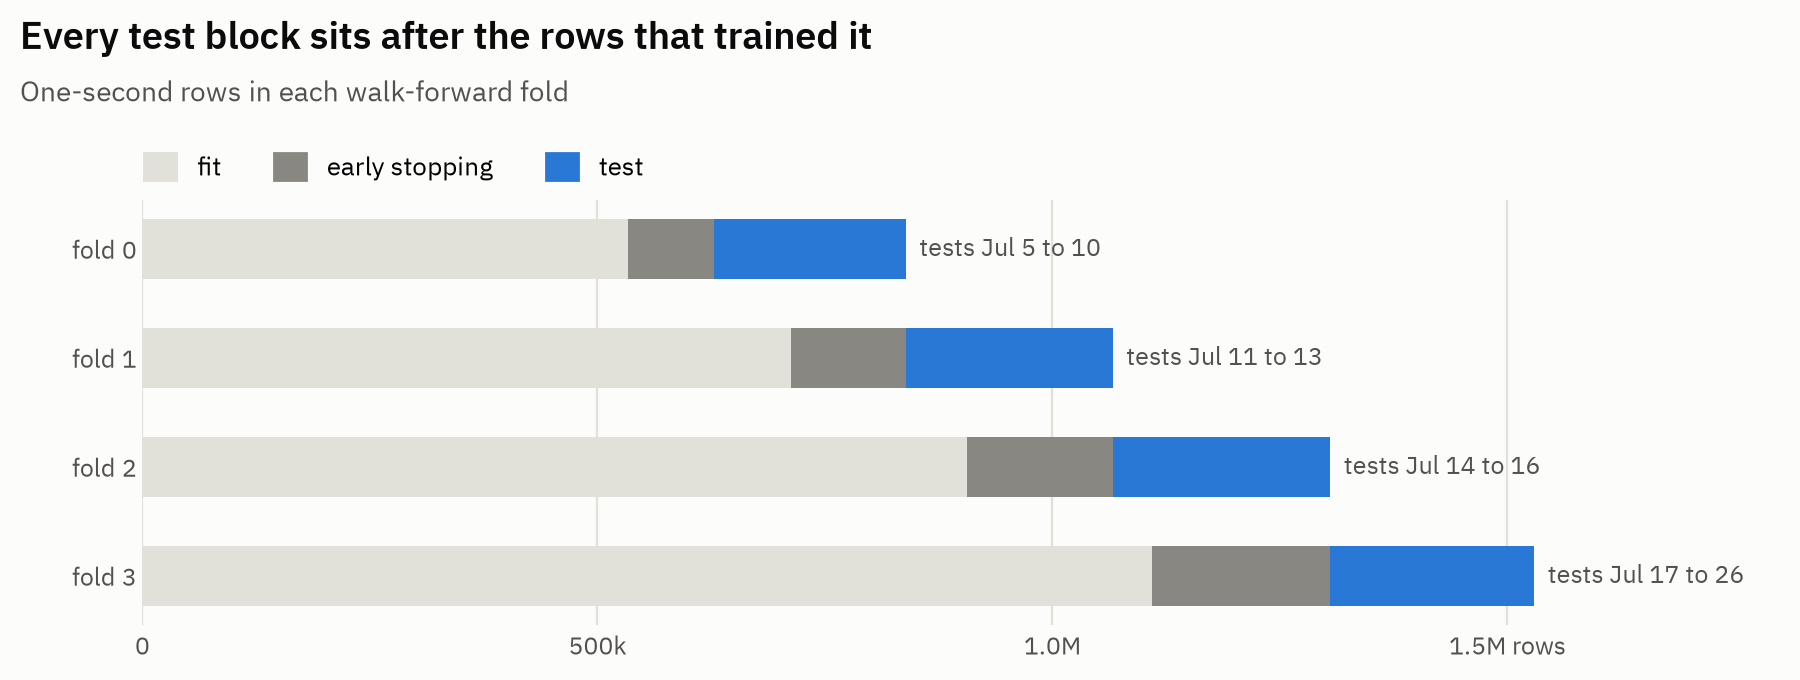

In [5]:
for i, fold in enumerate(real["folds"]):
    print(f"fold {i}: trains through {fold['train_dates'][-1][5:]} "
          f"({fold['n_val'] / (fold['n_train'] + fold['n_val']):.0%} of its rows kept for "
          f"early stopping), tests {', '.join(d[5:] for d in fold['test_dates'])}")
print(f"intervals: {spec['n_boot']:,} date-block draws")

day = np.array(spec["dates"], dtype="datetime64[D]")
holes = [(str(a + 1)[5:], str(b - 1)[5:]) for a, b in zip(day[:-1], day[1:]) if b - a > 1]
print(f"\ncapture is missing {' and '.join(f'{a} to {b}' for a, b in holes)}")

fig, ax = plt.subplots(figsize=(9, 3.4))
parts = (("fit", PALE), ("early stopping", MUTED), ("test", COINBASE))
for i, fold in enumerate(real["folds"]):
    y = len(real["folds"]) - 1 - i
    left = 0
    for (_, colour), n in zip(parts, (fold["n_train"], fold["n_val"], fold["n_test"])):
        ax.barh(y, n, left=left, height=0.55, color=colour, zorder=3)
        left += n
    first, last = day_labels([fold["test_dates"][0], fold["test_dates"][-1]])
    note(ax, left + 15000, y, f"tests {first} to {last}", va="center")
ax.set_yticks(range(len(real["folds"])),
              [f"fold {i}" for i in reversed(range(len(real["folds"])))])
ax.set_xticks([0, 500_000, 1_000_000, 1_500_000], ["0", "500k", "1.0M", "1.5M rows"])
ax.set_xlim(0, 1_800_000)
ax.tick_params(axis="x", length=0)
ax.spines["bottom"].set_visible(False)
ax.grid(axis="x")
# A key above the bars: the three parts are too narrow on most folds to name in place.
ax.legend([plt.Rectangle((0, 0), 1, 1, color=c) for _, c in parts], [p for p, _ in parts],
          loc="lower left", bbox_to_anchor=(-0.01, 1.0), ncol=3, handlelength=1.2,
          handleheight=1.2, fontsize=9.5, borderaxespad=0.3)
headline(fig, "Every test block sits after the rows that trained it",
         "One-second rows in each walk-forward fold", top=1.0, left=0.08, right=0.99,
         bottom=0.08)
plt.show()

Capture has two holes, 07-07 to 07-09 and 07-19 to 07-25, so the last fold trains through 07-16
and tests on 07-17, 07-18 and 07-26, across a week-long gap. The next section comes back to it.

## 4. The headline, and two models that did not make it

The essay reports the gradient-boosted tree, run alongside two ridge regressions on the same
folds, one on the order-flow features only and one on all 27. The intervals are recomputed from
the committed rows rather than read out of the record.

In [6]:
models = ["ridge_ofi", "ridge_all", "gbt"]
labels = ["ridge, order flow only", "ridge, all 27 features", "gradient boosting"]
pooled = {name: confidence_intervals(o) for name, o in
          read_oos(pl.read_parquet(DATA / "oos_real.parquet")).items()}

print(f"{'model':10s} {'R2 vs zero':>27s} {'hit rate':>25s}")
for name in models:
    r2, hit = pooled[name]["r2_vs_zero"], pooled[name]["hit_rate"]
    print(f"{name:10s} {r2[0]:8.5f} [{r2[1]:7.5f}, {r2[2]:7.5f}] "
          f"{hit[0]:7.4f} [{hit[1]:6.4f}, {hit[2]:6.4f}]")

# What the record said, and what the rows say, have to be the same thing.
for name in models:
    for metric in ("r2_vs_zero", "hit_rate"):
        assert np.allclose(pooled[name][metric], real["pooled"][name][metric], atol=1e-9), name
print("every interval matches the published record")

print(f"\n{'R2 by fold':10s} " + " ".join(f"{f'fold {i}':>7s}" for i in range(len(real["folds"]))))
for name in models:
    print(f"{name:10s} " + " ".join(f"{f['metrics'][name]['r2_vs_zero']:7.3f}"
                                    for f in real["folds"]))

model                       R2 vs zero                  hit rate
ridge_ofi   0.00070 [-0.09966, 0.04120]  0.7047 [0.6892, 0.7233]
ridge_all   0.03356 [-0.13461, 0.09921]  0.7352 [0.7150, 0.7585]
gbt         0.10349 [0.09075, 0.11202]  0.7572 [0.7351, 0.7805]
every interval matches the published record

R2 by fold  fold 0  fold 1  fold 2  fold 3
ridge_ofi    0.033   0.038   0.043  -0.206
ridge_all    0.091   0.077   0.098  -0.272
gbt          0.097   0.094   0.112   0.113


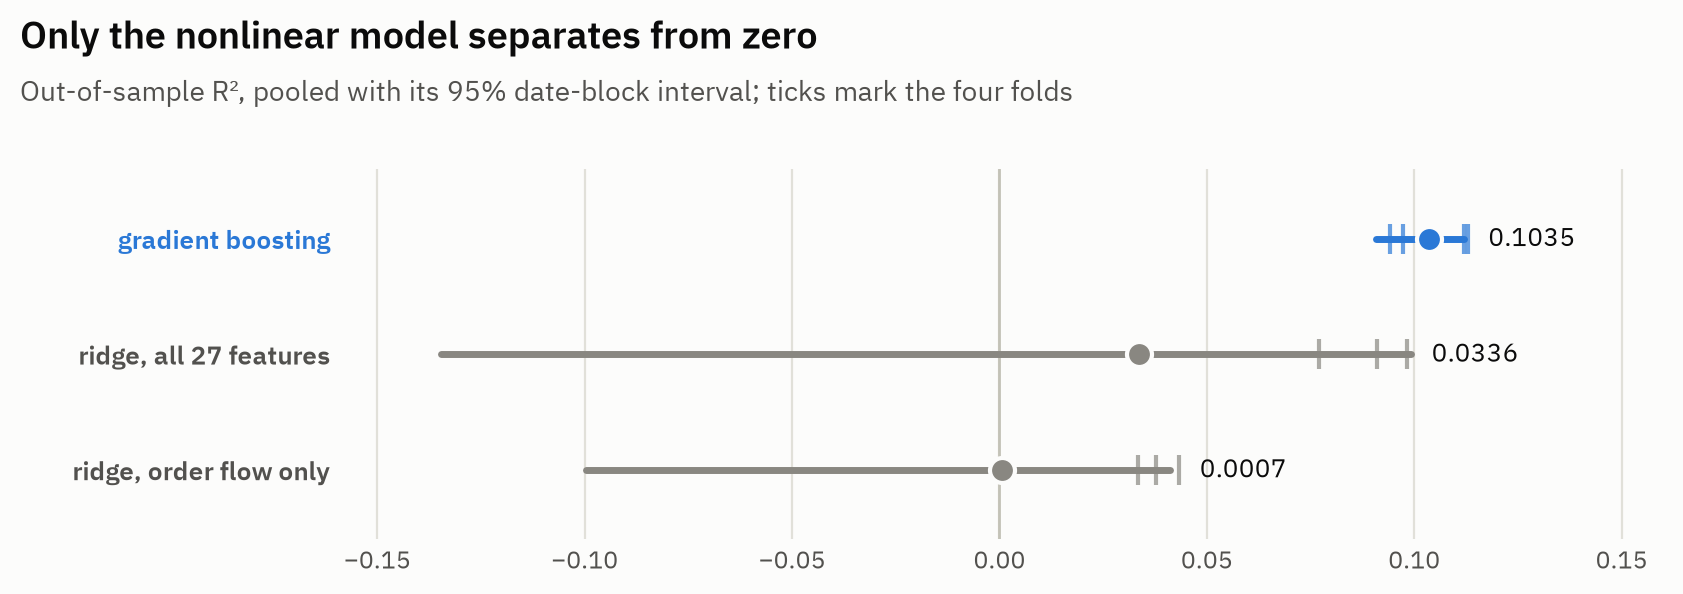

In [7]:
fig, ax = plt.subplots(figsize=(8.4, 3.0))
colours = [COINBASE if model == "gbt" else MUTED for model in models]
for i, (model, color) in enumerate(zip(models, colours)):
    folds = [f["metrics"][model]["r2_vs_zero"] for f in real["folds"]]
    # The value clears the folds' ticks as well as the interval.
    r2 = pooled[model]["r2_vs_zero"]
    interval(ax, i, r2, color, pad=max(0, max(folds) - r2[2]) + 0.005)
    ax.plot(folds, [i] * len(folds), "|", color=color, ms=11, mew=1.5, alpha=0.7, zorder=4)
ax.axvline(0, color=AXIS, lw=1)
categories(ax, labels, [INK2 if c == MUTED else c for c in colours])
ax.set_xlim(-0.16, 0.16)
ax.set_ylim(-0.6, 2.6)
headline(fig, "Only the nonlinear model separates from zero",
         "Out-of-sample R², pooled with its 95% date-block interval; ticks mark the four folds",
         top=0.85, left=0.2, right=0.99, bottom=0.1)
plt.show()

The tree's four folds sit between 0.094 and 0.113, so no one stretch of days carries its
average. The ridges are worth something on the first three folds and fail badly on the fourth,
the one tested across the capture gap, at -0.206 and -0.272. That drags their pooled scores
down to 0.001 and 0.034, with intervals well below zero, while the tree posts its best fold
there.

We read the difference as one of shape. Price impact is concave in size and depends on the
depth and spread an order lands in, so the same order-flow imbalance moves the price by
different amounts in different books, which a linear model cannot represent.

## 5. The reverse direction, and stale books

The reverse run changes only the direction, Kraken's book forecasting Coinbase, over the same
days, bars, feature builder, folds and model. Both directions are scored on the same test
dates, so besides comparing their intervals we can resample the difference itself, applying one
set of date draws to both.

In [8]:
forward_r2 = confidence_intervals(rows("real"))["r2_vs_zero"]
backward_r2 = confidence_intervals(rows("reverse"))["r2_vs_zero"]

print(f"Coinbase to Kraken   R2 {forward_r2[0]:8.5f} [{forward_r2[1]:.5f}, {forward_r2[2]:.5f}]")
print(f"Kraken to Coinbase   R2 {backward_r2[0]:8.5f} [{backward_r2[1]:.5f}, {backward_r2[2]:.5f}]")
print(f"\nratio of point estimates: {forward_r2[0] / backward_r2[0]:.1f}x")

fwd, rev = rows("real"), rows("reverse")
shared = np.intersect1d(np.unique(fwd.dates), np.unique(rev.dates))


def r2_on_shared(o):
    """R2 vs zero on the shared dates: the estimate, and its value under every draw."""
    keep = np.isin(o.dates, shared)
    blocks = Blocks(o.dates[keep], n_boot=20_000)
    y, pred = o.y[keep], o.pred[keep]
    point = 1 - ((y - pred) ** 2).sum() / (y ** 2).sum()
    return blocks, point, 1 - blocks.drawn((y - pred) ** 2) / blocks.drawn(y ** 2)


fwd_blocks, fwd_point, fwd_draws = r2_on_shared(fwd)
rev_blocks, rev_point, rev_draws = r2_on_shared(rev)
assert np.array_equal(fwd_blocks.weights, rev_blocks.weights), "the draws are not paired"

delta = fwd_draws - rev_draws
lo, hi = np.percentile(delta, [2.5, 97.5])
print(f"\npaired over {len(shared)} shared test dates")
print(f"  delta R2 {fwd_point - rev_point:.4f}  95% [{lo:.4f}, {hi:.4f}]")
print(f"  draws at or below zero: {int((delta <= 0).sum()):,} of {len(delta):,}")

assert backward_r2[2] < forward_r2[1], "the two directions' intervals overlap"
assert lo > 0, "the paired difference reaches zero"

Coinbase to Kraken   R2  0.10349 [0.09075, 0.11202]
Kraken to Coinbase   R2  0.01076 [0.00814, 0.01437]

ratio of point estimates: 9.6x



paired over 12 shared test dates
  delta R2 0.0927  95% [0.0785, 0.1026]
  draws at or below zero: 0 of 20,000


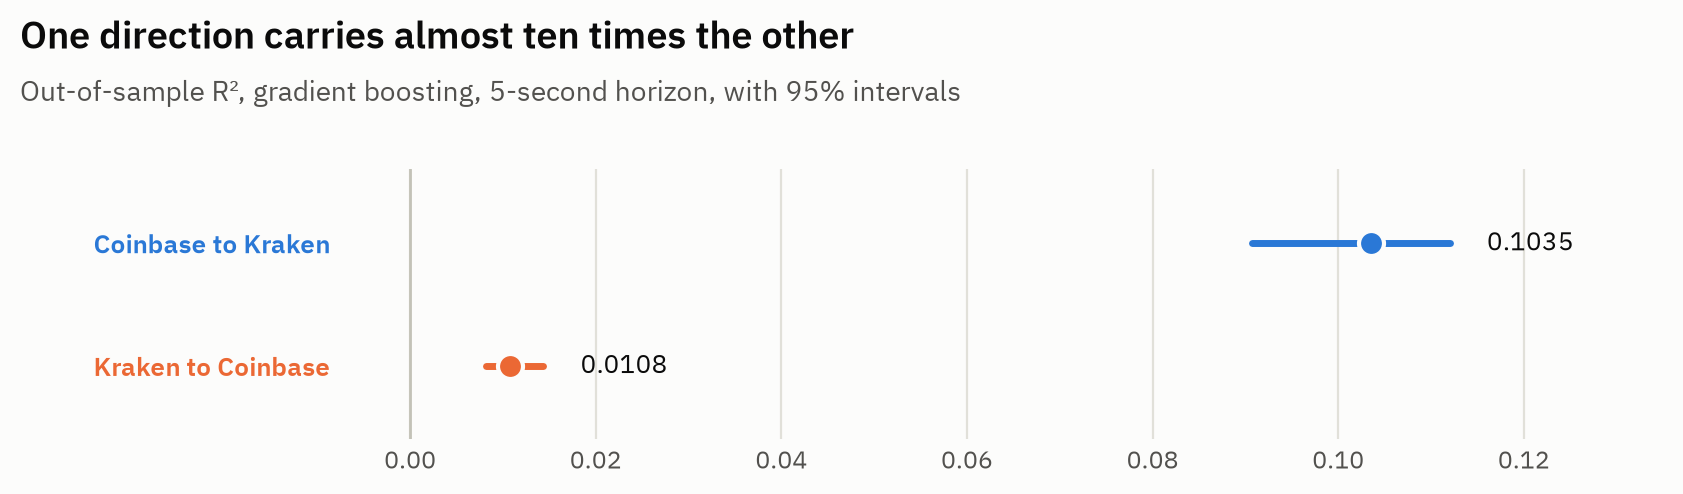

In [9]:
fig, ax = plt.subplots(figsize=(8.4, 2.5))
interval(ax, 1, forward_r2, COINBASE)
interval(ax, 0, backward_r2, KRAKEN)
ax.axvline(0, color=AXIS, lw=1)
categories(ax, ["Kraken to Coinbase", "Coinbase to Kraken"], [KRAKEN, COINBASE])
ax.set_xlim(-0.008, 0.135)
ax.set_ylim(-0.6, 1.6)
headline(fig, "One direction carries almost ten times the other",
         "Out-of-sample R², gradient boosting, 5-second horizon, with 95% intervals",
         top=0.85, left=0.2, right=0.99, bottom=0.12)
plt.show()

Coinbase's book forecasts Kraken 9.6 times better than the reverse, and the paired difference,
0.0927, has none of its 20,000 draws at or below zero. Anything symmetric between the two
directions, a shared factor moving both books or a leak in the machinery both runs share, would
inflate both alike and could not open a gap this wide. A leak in one venue's features alone
would not show here; section 6 tests for that.

The sharper worry is stale data. If a feature row may carry a quote up to five seconds old,
"forecasting" the next five seconds could be recovering a move that had already happened at
Kraken but not yet been recorded. So both runs were repeated with the staleness cut tightened,
down to both books current within 200 ms.

In [10]:
FRESHNESS = DATA / "freshness"
sweep = {}
for f in sorted(FRESHNESS.glob("record_*.json")):
    r = json.loads(f.read_text(encoding="utf-8"))
    sweep[r["spec"]["predict_venue"], r["spec"]["max_age_ms"]] = r
for venue, tag in (("kraken", real), ("coinbase", backward)):
    sweep[venue, tag["spec"]["max_age_ms"]] = tag

cuts = sorted({age for _, age in sweep})
print(f"{'cut':>7} {'kept':>7}   {'Coinbase to Kraken':>26}   {'Kraken to Coinbase':>26}   ratio")
for age in cuts:
    ahead, behind = sweep["kraken", age], sweep["coinbase", age]
    f = ahead["pooled"]["gbt"]["r2_vs_zero"]
    b = behind["pooled"]["gbt"]["r2_vs_zero"]
    kept = ahead["n_rows"] / ahead["n_rows_before"]
    print(f"{age:>5}ms {kept:>7.1%}   {f[0]:.5f} [{f[1]:.5f}, {f[2]:.5f}]   "
          f"{b[0]:.5f} [{b[1]:.5f}, {b[2]:.5f}]   {f[0] / b[0]:>4.1f}x")
forward_by_cut = [sweep["kraken", age]["pooled"]["gbt"]["r2_vs_zero"][0] for age in cuts]
print(f"\nacross a {max(cuts) // min(cuts)}-fold range of cuts, the forward R2 runs from "
      f"{min(forward_by_cut):.3f} to {max(forward_by_cut):.3f}")

# Every run in the sweep has to be the same code over the same data as the headline, or
# the comparison is between two different experiments rather than two freshness cuts.
for (venue, age), r in sweep.items():
    p = r["provenance"]
    assert not p["git_dirty"], f"{venue} @ {age}ms was recorded from a dirty tree"
    assert p["builder_fingerprint"] == real["provenance"]["builder_fingerprint"]
    assert p["source_fingerprints"] == real["provenance"]["source_fingerprints"]

tightest = min(cuts)
assert (
    sweep["kraken", tightest]["pooled"]["gbt"]["r2_vs_zero"][0]
    > 5 * sweep["coinbase", tightest]["pooled"]["gbt"]["r2_vs_zero"][0]
), "the asymmetry does not survive the tightest freshness cut"

print()
for tag, venue in (("real", "Kraken"), ("reverse", "Coinbase")):
    print(f"{venue}'s mid moves on {(rows(tag).y != 0).mean():.1%} of scored 5-second bars")

    cut    kept           Coinbase to Kraken           Kraken to Coinbase   ratio
  200ms   54.4%   0.10284 [0.09328, 0.11062]   0.01291 [0.01053, 0.01622]    8.0x
  500ms   75.1%   0.10476 [0.09209, 0.11563]   0.01229 [0.00987, 0.01543]    8.5x
 1000ms   85.3%   0.10377 [0.09421, 0.11148]   0.01154 [0.00951, 0.01461]    9.0x
 5000ms   92.6%   0.10349 [0.09075, 0.11202]   0.01076 [0.00814, 0.01437]    9.6x

across a 25-fold range of cuts, the forward R2 runs from 0.103 to 0.105

Kraken's mid moves on 21.1% of scored 5-second bars
Coinbase's mid moves on 58.8% of scored 5-second bars


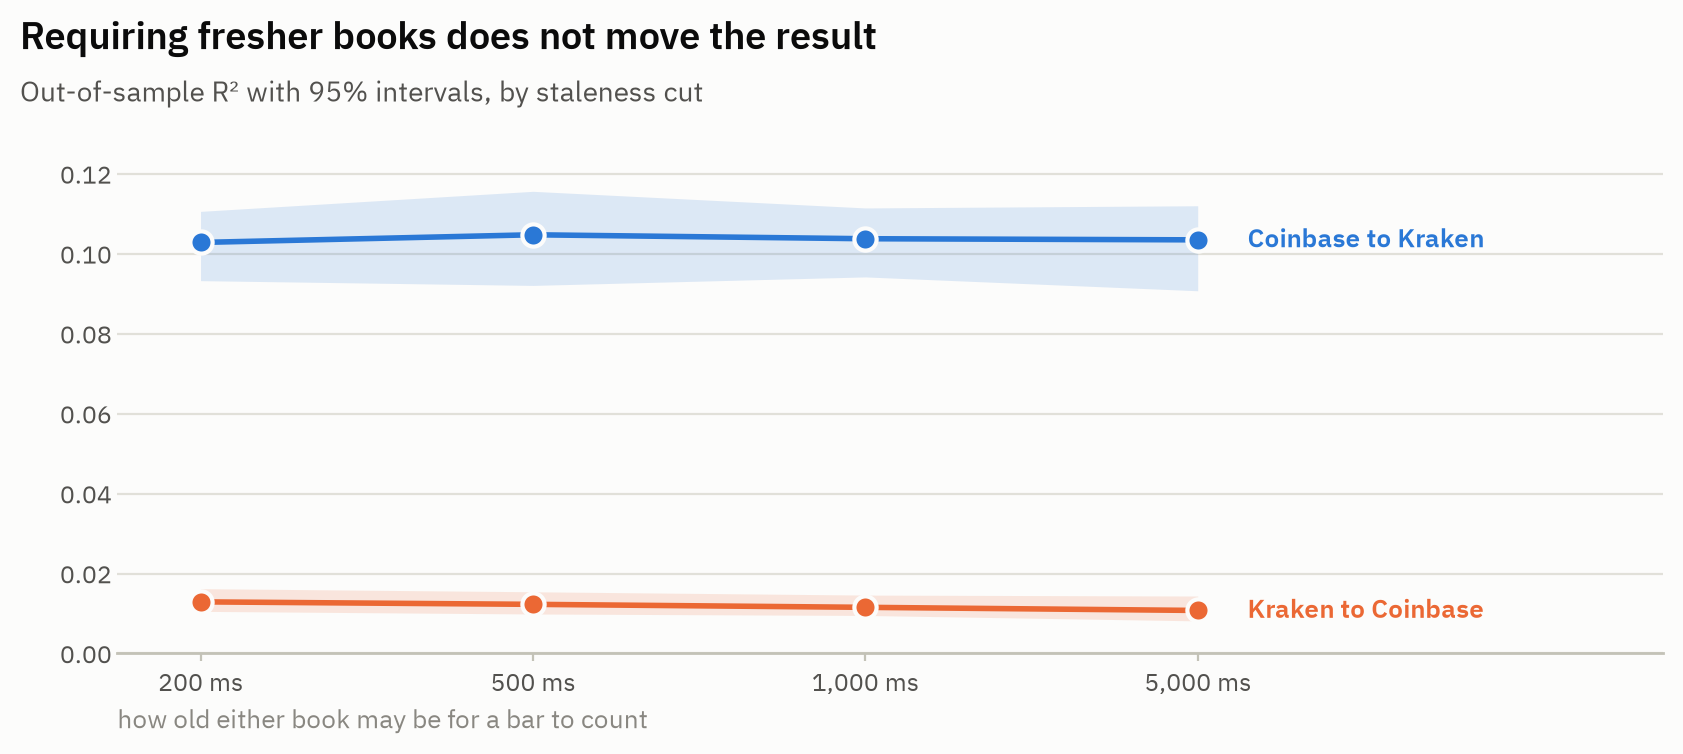

In [11]:
fig, ax = plt.subplots(figsize=(8.4, 3.8))
xs = range(len(cuts))
for venue, colour, label in (("kraken", COINBASE, "Coinbase to Kraken"),
                             ("coinbase", KRAKEN, "Kraken to Coinbase")):
    pts = [sweep[venue, age]["pooled"]["gbt"]["r2_vs_zero"] for age in cuts]
    ax.plot(xs, [p[0] for p in pts], "o-", color=colour, lw=2, ms=8, mec=SURFACE, mew=1.5,
            zorder=4)
    ax.fill_between(xs, [p[1] for p in pts], [p[2] for p in pts],
                    color=colour, alpha=0.15, lw=0, zorder=3)
    name_series(ax, len(cuts) - 0.85, pts[-1][0], label, colour)
ax.set_xticks(list(xs), [f"{age:,} ms" for age in cuts])
ax.set_xlim(-0.25, len(cuts) + 0.4)
ax.set_ylim(bottom=0)
ax.yaxis.set_major_formatter("{x:.2f}")
ax.set_xlabel("how old either book may be for a bar to count", loc="left")
ax.grid(axis="y")
headline(fig, "Requiring fresher books does not move the result",
         "Out-of-sample R² with 95% intervals, by staleness cut", top=0.85, left=0.07,
         right=0.99, bottom=0.14)
plt.show()

Across a 25-fold tightening of the cut the forward R² stays between 0.103 and 0.105, and the
ratio between the directions between 8.0 and 9.6, down to 200 ms, which keeps 54.4% of bars.

Neither check separates a venue where news arrives first from one that requotes less often.
Kraken is the coarser book, its mid moving on 21.1% of five-second bars against Coinbase's
58.8%, and a quote can be current and still rarely updated. That is the question the essay sets
aside.

## 6. Leakage: the displaced target

A forecasting pipeline can look good by accident: a feature window that reaches one bar too
far, a fold boundary off by one, a target that shares a term with an input. The test for that
whole family is to break the target on purpose, rerunning the same pipeline with the target
displaced by 3600 bars, an hour, within each day. Every feature, fold, hyperparameter and line
of code is unchanged, and nothing in the inputs can know the displaced return's direction.

In [12]:
null_r2 = confidence_intervals(rows("placebo"))["r2_vs_zero"]
null_hit = confidence_intervals(rows("placebo"))["hit_rate"]

print(f"target displaced by {placebo['spec']['placebo_lag_bars']} bars")
print(f"  R2  {null_r2[0]:8.5f} [{null_r2[1]:.5f}, {null_r2[2]:.5f}]")
print(f"  hit {null_hit[0]:8.4f} [{null_hit[1]:.4f}, {null_hit[2]:.4f}]")

# The gate. Both have to come back indistinguishable from chance.
assert null_r2[1] < 0 < null_r2[2], f"placebo R2 interval misses zero: {null_r2}"
assert null_hit[1] < 0.52, "placebo hit rate is above the long-bias floor"
print("\nthe null holds: R2 straddles zero, hit rate sits at a coin flip")

target displaced by 3600 bars
  R2  -0.00010 [-0.00028, 0.00011]
  hit   0.5035 [0.4958, 0.5124]

the null holds: R2 straddles zero, hit rate sits at a coin flip


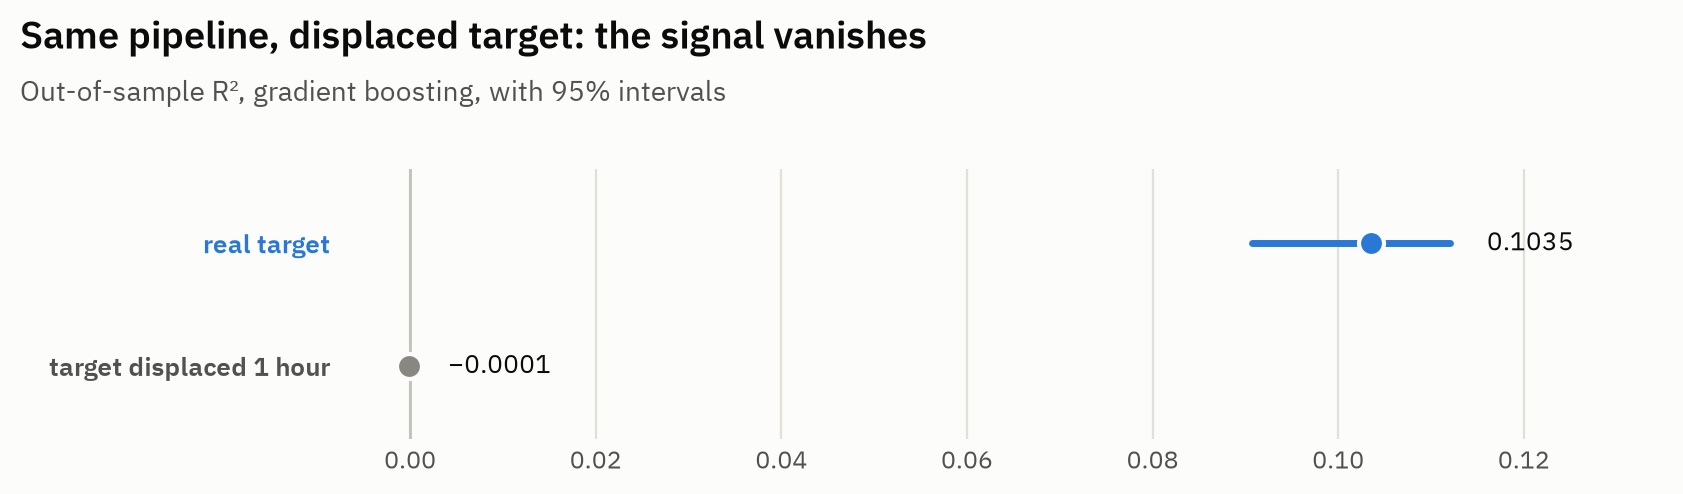

In [13]:
fig, ax = plt.subplots(figsize=(8.4, 2.5))
interval(ax, 1, forward_r2, COINBASE)
interval(ax, 0, null_r2, MUTED)
ax.axvline(0, color=AXIS, lw=1)
categories(ax, ["target displaced 1 hour", "real target"], [INK2, COINBASE])
ax.set_xlim(-0.008, 0.135)
ax.set_ylim(-0.6, 1.6)
headline(fig, "Same pipeline, displaced target: the signal vanishes",
         "Out-of-sample R², gradient boosting, with 95% intervals", top=0.85, left=0.2,
         right=0.99, bottom=0.12)
plt.show()

Displaced, the forecast scores an R² of -0.0001 with an interval straddling zero, and its hit
rate of 50.4% is a coin flip. The test covers alignment leaks like those listed above. A leak
at the scale of a whole day, such as a statistic computed over the full session, would survive
an hour's displacement and is not covered.

## 7. Calibration

R² against zero already punishes a forecast that is too large overall, but it does not show
where along the range of predictions the calibration slips. We bin the out-of-sample
predictions into 20 equal-count buckets and plot each bucket's mean prediction against its mean
realized return, then fit the same line on the raw rows (Mincer-Zarnowitz), with standard
errors clustered by date.

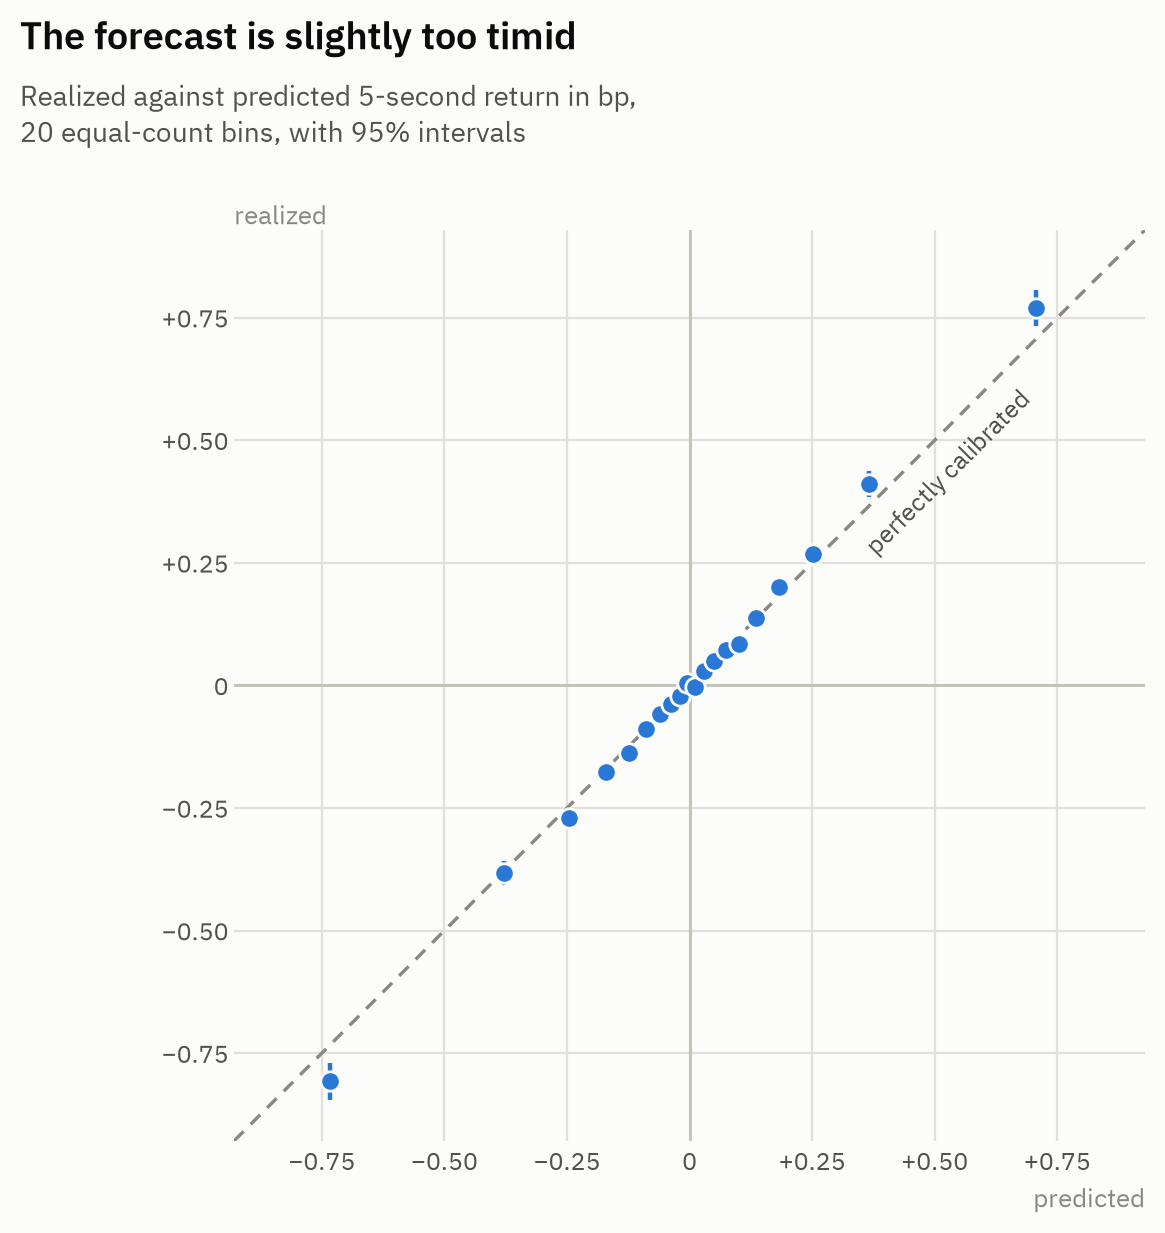

slope across the 20 bins: 1.083
Mincer-Zarnowitz on raw rows, 12 date clusters:
  intercept -0.0003 bps (SE 0.0023)
  slope     1.086 (SE 0.030), t against 1 = 2.90
a forecast of 0.5 bps is followed by 0.54 bps on average


In [14]:
o = rows("real")
edges = np.quantile(o.pred, np.linspace(0, 1, 21))
bucket = np.clip(np.digitize(o.pred, edges[1:-1]), 0, 19)
mean_pred = np.array([o.pred[bucket == b].mean() for b in range(20)])
mean_y = np.array([o.y[bucket == b].mean() for b in range(20)])
sem = np.array([o.y[bucket == b].std() / np.sqrt((bucket == b).sum()) for b in range(20)])
slope = float(np.polyfit(mean_pred, mean_y, 1)[0])

fig, ax = plt.subplots(figsize=(6, 6.2))
lim = max(abs(mean_pred).max(), abs(mean_y).max()) * 1.15
ax.plot([-lim, lim], [-lim, lim], color=MUTED, lw=1.2, ls=(0, (4, 3)), zorder=2)
note(ax, 0.55 * lim, 0.55 * lim - 0.06, "perfectly calibrated", rotation=45,
     rotation_mode="anchor", ha="center", va="top")
ax.errorbar(mean_pred, mean_y, yerr=1.96 * sem, fmt="o", color=COINBASE, ms=7, lw=1.6,
            capsize=0, mec=SURFACE, mew=1, zorder=4)
ax.axhline(0, color=AXIS, lw=1, zorder=1)
ax.axvline(0, color=AXIS, lw=1, zorder=1)
ax.set_xlim(-lim, lim)
ax.set_ylim(-lim, lim)
ax.set_aspect("equal")
for axis in (ax.xaxis, ax.yaxis):
    axis.set_major_locator(mpl.ticker.MultipleLocator(0.25))
    axis.set_major_formatter(signed(digits=2))
ax.tick_params(axis="x", length=0)
ax.spines["bottom"].set_visible(False)
ax.grid()
ax.set_xlabel("predicted", loc="right")
note(ax, -lim, lim, "realized", ha="left", va="bottom", color=MUTED, fontsize=9.5)
headline(fig, "The forecast is slightly too timid",
         "Realized against predicted 5-second return in bp,\n20 equal-count bins, with 95% intervals",
         top=1.15, left=0.17, right=0.97, bottom=0.08)
plt.show()

# Standard errors clustered by date, since bars within one day are not independent draws.
X = np.column_stack([np.ones_like(o.pred), o.pred])
beta = np.linalg.lstsq(X, o.y, rcond=None)[0]
resid = o.y - X @ beta
bread = np.linalg.inv(X.T @ X)
meat = sum(
    np.outer(u, u)
    for u in (X[o.dates == d].T @ resid[o.dates == d] for d in np.unique(o.dates))
)
se = np.sqrt(np.diag(bread @ meat @ bread))

print(f"slope across the 20 bins: {slope:.3f}")
print(f"Mincer-Zarnowitz on raw rows, {len(np.unique(o.dates))} date clusters:")
print(f"  intercept {beta[0]:.4f} bps (SE {se[0]:.4f})")
print(f"  slope     {beta[1]:.3f} (SE {se[1]:.3f}), t against 1 = {(beta[1] - 1) / se[1]:.2f}")
print(f"a forecast of 0.5 bps is followed by {beta[0] + 0.5 * beta[1]:.2f} bps on average")

The slope is 1.086, about three standard errors above one on 12 date clusters, and the
intercept, -0.0003 bps, is well inside its standard error. So the forecast is too timid by a
near-constant factor: when it says half a basis point, 0.54 follows on average. A constant
scale error leaves the ranking of bars untouched, and the ranking is what the next section
measures.

## 8. Where the accuracy concentrates

Averaging over every bar hides whether the model knows when it knows. Two definitions make that
measurable. A move counts only if it exceeds half the prevailing spread on Kraken; smaller
moves fall in a dead zone and score as no move. And the model's threshold is set so that it
calls a fixed share of bars, from 2% to 50%, with precision measured at each. Fixing the share
keeps the comparison with the displaced control fair, since a model that calls few bars is
answering an easier question than one that calls most of them.

In [15]:
spot = coverage_confidence_intervals(rows("real"), 0.02)["up_precision"]
published = real["selectivity"][0]["metrics"]["up_precision"]
assert np.allclose(spot, published, atol=1e-9)
print(f"recomputed precision at 2% coverage: {spot[0]:.4f} [{spot[1]:.4f}, {spot[2]:.4f}] "
      f"(matches the record)")

base = real["base_rates"]["up"]
null_base = placebo["base_rates"]["up"]
print(f"\n{'coverage':>9s} {'real':>25s} {'lift':>6s} {'displaced':>25s} {'lift':>6s}")
for s_real, s_null in zip(real["selectivity"], placebo["selectivity"]):
    r = s_real["metrics"]["up_precision"]
    n = s_null["metrics"]["up_precision"]
    print(f"{s_real['coverage']:>8.0%} {r[0]:7.4f} [{r[1]:.4f}, {r[2]:.4f}] {r[0] / base:5.1f}x "
          f"{n[0]:7.4f} [{n[1]:.4f}, {n[2]:.4f}] {n[0] / null_base:5.1f}x")
# Each run has its own base rate: displacing the target changes which bars cleared half a
# spread, so lift is measured against the run's own floor rather than a shared one.
print(f"\nbase rate, share of bars that rose more than half a spread:"
      f"  real {base:.4f}   displaced {null_base:.4f}")

o = rows("real")
assert np.isclose((o.y > o.threshold).mean(), base)
print(f"dead zone: median threshold {np.median(o.threshold):.4f} bps; "
      f"{(np.abs(o.y) > o.threshold).mean():.1%} of bars clear it, {(o.y != 0).mean():.1%} move")

recomputed precision at 2% coverage: 0.5257 [0.4873, 0.5707] (matches the record)

 coverage                      real   lift                 displaced   lift
      2%  0.5257 [0.4873, 0.5707]   5.2x  0.1403 [0.0862, 0.1770]   1.3x
      5%  0.4565 [0.4285, 0.4789]   4.5x  0.1456 [0.1097, 0.1637]   1.4x
     10%  0.3940 [0.3736, 0.4077]   3.9x  0.1439 [0.1176, 0.1587]   1.4x
     25%  0.3028 [0.2811, 0.3184]   3.0x  0.1215 [0.0942, 0.1464]   1.2x
     50%  0.2290 [0.2041, 0.2475]   2.2x  0.1075 [0.0852, 0.1287]   1.0x

base rate, share of bars that rose more than half a spread:  real 0.1019   displaced 0.1051
dead zone: median threshold 0.0078 bps; 19.8% of bars clear it, 21.1% move


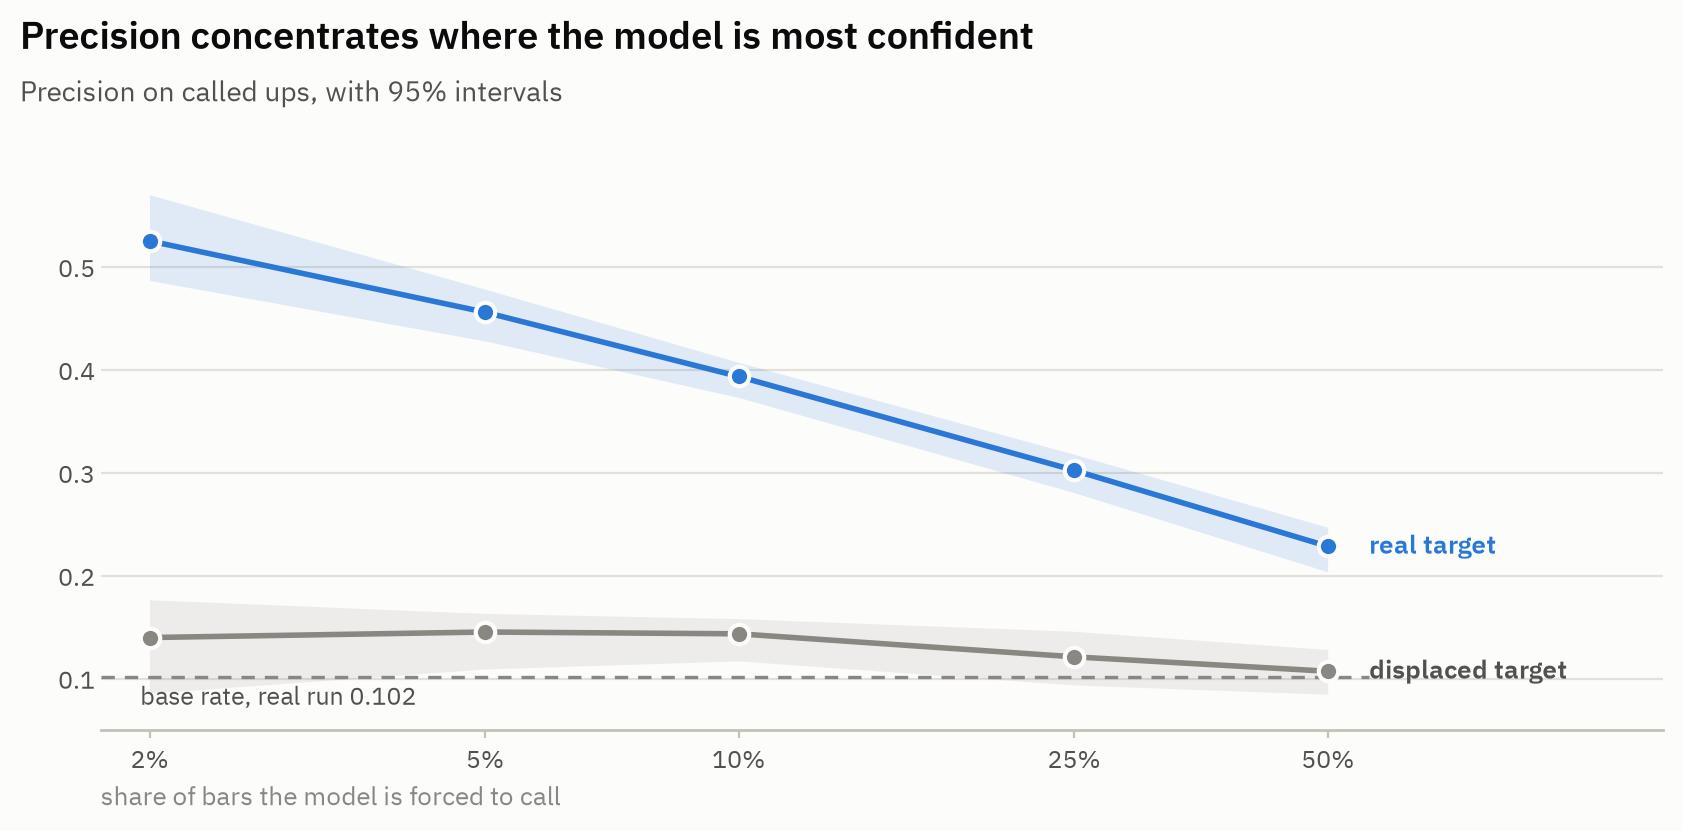

In [16]:
fig, ax = plt.subplots(figsize=(8.4, 4.2))
for rec, color, label in [(real, COINBASE, "real target"), (placebo, MUTED, "displaced target")]:
    cov = [s["coverage"] for s in rec["selectivity"]]
    band = np.array([s["metrics"]["up_precision"] for s in rec["selectivity"]])
    ax.fill_between(cov, band[:, 1], band[:, 2], color=color, alpha=0.13, lw=0)
    ax.plot(cov, band[:, 0], "-o", color=color, lw=2, ms=7, mec=SURFACE, mew=1.5, zorder=4)
    name_series(ax, cov[-1] * 1.12, band[-1, 0], label, INK2 if color == MUTED else color)
# Stopped short of the labels, so neither sits on it.
ax.hlines(base, 0.0175, 0.56, color=MUTED, lw=1.2, ls=(0, (4, 3)), zorder=2)
note(ax, 0.0195, base - 0.008, f"base rate, real run {base:.3f}", va="top")
ax.set_xscale("log")
ax.minorticks_off()
ax.set_xticks([0.02, 0.05, 0.10, 0.25, 0.50], ["2%", "5%", "10%", "25%", "50%"])
ax.set_xlim(0.0175, 1.25)
ax.set_ylim(0.05, None)
ax.yaxis.set_major_formatter("{x:.1f}")
ax.set_xlabel("share of bars the model is forced to call", loc="left")
ax.grid(axis="y")
headline(fig, "Precision concentrates where the model is most confident",
         "Precision on called ups, with 95% intervals", top=0.85, left=0.06, right=0.99,
         bottom=0.13)
plt.show()

Forced to call half of all bars, the model's precision on up-calls is 2.2 times the base rate,
and on its most confident 2% it is 5.2 times: the steady climb of a genuine ranking. The
displaced control climbs from 1.0 to 1.4 times its own base rate and then stops, flat where the
real curve is steepest. Volatility clusters, so a model can learn to call more often when the
book is active, but that ranks bars by *when* something will happen, not *which way*.

Half a spread is a low bar on a book this tight: the median threshold is 0.0078 bps, and 19.8%
of bars clear it against the 21.1% that move at all, so precision here is close to precision on
any move.

## 9. Holes in the recording

The prices skip every second in which either book was stale or the capture was down, and
crosstick's estimator, which made the run records, fits straight across a skipped stretch as if
the prices either side were one second apart. Across a hole of minutes or hours both prices can
move a long way, so the model sees a single second in which both venues jumped together: the
pattern that widens Hasbrouck's bounds.

The essay fits each day only on the seconds whose previous ten were all kept. The function
below fits either way, and keeping every row it returns crosstick's recorded estimates exactly.

In [17]:
from datetime import datetime, timezone
from types import SimpleNamespace

venues = tuple(real["spec"]["infoshare_venues"])


def unbroken(step=1, panel=prices):
    """Each day's log prices on bars `step` seconds apart and aligned to the clock, and which
    bars follow on from the bar before with none missing in between."""
    out = {}
    for (d,), g in panel.group_by(["date"], maintain_order=True):
        g = g.filter(pl.col("ts_ns") % (step * 1_000_000_000) == 0)
        whole = np.r_[False, np.diff(g["ts_ns"].to_numpy()) == step * 1_000_000_000]
        out[d] = (np.log(g.select(["coinbase_mid", "kraken_mid"]).to_numpy()), whole)
    return out


def vecm(p, whole=None, lags=10):
    """crosstick's error-correction fit and Coinbase's Hasbrouck bounds, in numpy. With
    `whole`, a step is used only if it and the `lags` steps before it each span exactly one
    bar. Without it every row is used, which is what crosstick's estimator does."""
    dp = np.diff(p, axis=0)
    t = np.arange(lags, len(dp))
    if whole is not None:
        stretch = np.cumsum(~whole)
        t = t[stretch[t - lags] == stretch[t + 1]]
    X = np.column_stack([p[t, 0] - p[t, 1], *(dp[t - k] for k in range(1, lags + 1)),
                         np.ones(len(t))])
    coef, *_ = np.linalg.lstsq(X, dp[t], rcond=None)
    resid = dp[t] - X @ coef
    alpha, omega = coef[0], np.cov(resid, rowvar=False)
    psi = np.array([alpha[1], -alpha[0]]) / (alpha[1] - alpha[0])
    coinbase = []
    for order in ([0, 1], [1, 0]):
        piece = (psi[order] @ np.linalg.cholesky(omega[np.ix_(order, order)])) ** 2
        coinbase.append(piece[order.index(0)] / (psi @ omega @ psi))
    return SimpleNamespace(n=len(t), alpha=alpha, pulls=np.array([-alpha[0], alpha[1]]),
                           bounds=np.sort(np.clip(coinbase, 0, 1)),
                           corr=omega[0, 1] / np.sqrt(omega[0, 0] * omega[1, 1]))


one = unbroken(1)
days = {d: p for d, (p, _) in one.items()}
across = {d: vecm(p) for d, p in days.items()}
skipping = {d: vecm(p, whole) for d, (p, whole) in one.items()}

# Keeping every row, the function is crosstick's estimator, so it returns the record.
recorded = next(b for b in real["infoshare"] if b["stride"] == 1)["estimates"]
for e in recorded:
    f = across[e["date"]]
    assert f.n == e["n"] and np.allclose(f.alpha, e["alpha"], rtol=1e-9, atol=0)
    assert np.allclose(f.bounds, e["bounds"][0], atol=1e-9)
print(f"keeping every row, the fit returns crosstick's recorded estimate on all "
      f"{len(recorded)} days")
used, moves = sum(f.n for f in skipping.values()), sum(f.n for f in across.values())
print(f"skipping holes, it uses {used:,} of the {moves:,} one-second moves, leaving out the "
      f"{moves - used:,} ({1 - used / moves:.1%}) with a missing second in their last ten\n")

steps = prices.with_columns(
    step=pl.col("ts_ns").diff().over("date") / 1e9,
    coinbase=pl.col("coinbase_mid").log().diff().over("date") * 1e4,
    kraken=pl.col("kraken_mid").log().diff().over("date") * 1e4,
).filter(pl.col("step") > 1)
holes = {d: g for (d,), g in steps.group_by(["date"])}
print(f"{'':5s} {'holes':>5s} {'longest':>8s} {'largest move':>12s}   {'lower bound':>17s}   "
      f"{'shock corr':>15s}")
print(f"{'':5s} {'':5s} {'':8s} {'across one':>12s}   {'across':>8s} {'skipping':>8s}   "
      f"{'across':>7s} {'skipping':>7s}")
for d in days:
    h = holes[d]
    move = h.select(pl.max_horizontal(pl.col("coinbase").abs(), pl.col("kraken").abs()).max()).item()
    print(f"{d[5:]:5s} {h.height:>5d} {h['step'].max():>7,.0f}s {move:>10.0f}bp   "
          f"{across[d].bounds[0]:>8.3f} {skipping[d].bounds[0]:>8.3f}   "
          f"{across[d].corr:>7.2f} {skipping[d].corr:>7.2f}")

big = steps.with_columns(size=pl.max_horizontal(pl.col("coinbase").abs(), pl.col("kraken").abs())) \
    .sort("size")[-1]
start = datetime.fromtimestamp((big["ts_ns"].item() - big["step"].item() * 1e9) / 1e9, timezone.utc)
end = datetime.fromtimestamp(big["ts_ns"].item() / 1e9, timezone.utc)
print(f"\nthe largest move across a hole: {big['date'].item()[5:]}, {big['step'].item():,.0f}s from "
      f"{start:%H:%M} to {end:%H:%M} UTC, Coinbase {big['coinbase'].item():+.0f}bp, "
      f"Kraken {big['kraken'].item():+.0f}bp")

change = {d: skipping[d].bounds[0] - across[d].bounds[0] for d in days if d != big["date"].item()}
print(f"on the other {len(change)} days, skipping holes moves the lower bound by "
      f"{min(change.values()):+.3f} to {max(change.values()):+.3f}\n")

summary = {}
for name, fits in (("across holes, as recorded", across), ("skipping holes", skipping)):
    b, a = np.array([f.bounds for f in fits.values()]), np.array([f.pulls for f in fits.values()])
    summary[name] = (f"[{b[:, 0].mean():.3f}, {b[:, 1].mean():.3f}] {(b[:, 0] < 0.5).sum()} "
                     f"{a[:, 1].mean() / a[:, 0].mean():.0f}")
    print(f"{name:26s} bounds [{b[:, 0].mean():.3f}, {b[:, 1].mean():.3f}], shock correlation "
          f"{np.mean([f.corr for f in fits.values()]):.2f}, lower bound below 0.5 on "
          f"{(b[:, 0] < 0.5).sum()} of {len(b)} days, Kraken's pull "
          f"{a[:, 1].mean() / a[:, 0].mean():.0f} times Coinbase's")

# The text below quotes these.
assert f"{moves - used:,} {1 - used / moves:.1%}" == "38,296 2.5%"
assert f"{big['date'].item()} {big['step'].item():,.0f} {start:%H:%M} {end:%H:%M} " \
       f"{big['coinbase'].item():.0f} {big['kraken'].item():.0f}" == \
    "2026-07-14 9,855 12:22 15:07 205 203"
d = big["date"].item()
assert f"{across[d].bounds[0]:.3f} {across[d].corr:.2f} {skipping[d].bounds[0]:.3f} " \
       f"{skipping[d].corr:.2f}" == "0.292 0.84 0.785 0.44"
assert f"{min(change.values()):+.3f} {max(change.values()):+.3f}" == "-0.055 +0.069"
assert summary == {"across holes, as recorded": "[0.720, 0.997] 1 21",
                   "skipping holes": "[0.754, 0.997] 0 17"}

keeping every row, the fit returns crosstick's recorded estimate on all 20 days
skipping holes, it uses 1,490,818 of the 1,529,114 one-second moves, leaving out the 38,296 (2.5%) with a missing second in their last ten



      holes  longest largest move         lower bound        shock corr
                       across one     across skipping    across skipping
06-27   254     702s         11bp      0.701    0.697      0.46    0.45
06-28   163     705s          6bp      0.650    0.651      0.52    0.53
06-29   161     654s         19bp      0.547    0.545      0.61    0.61
06-30   117     626s         41bp      0.613    0.629      0.58    0.56
07-01   311     650s         34bp      0.572    0.595      0.62    0.60
07-02   399     642s         30bp      0.611    0.654      0.63    0.59
07-03   216     655s         39bp      0.719    0.755      0.54    0.48
07-04   178     638s          7bp      0.812    0.821      0.41    0.41
07-05   165      53s          4bp      0.759    0.758      0.46    0.47
07-06   160   2,650s         28bp      0.640    0.668      0.55    0.52
07-10   291   3,835s         37bp      0.758    0.776      0.45    0.42
07-11   492   5,367s         34bp      0.835    0.780      0.34

Skipping holes leaves out 38,296 of the one-second moves, 2.5% of them, and one hole accounts
for most of the change. On 07-14 the capture lost 9,855 seconds, from 12:22 to 15:07 UTC,
across which Coinbase's price rose 205 bp and Kraken's 203. Fitted across it, the day's lower
bound is 0.292 and its shock correlation 0.84; fitted without it, 0.785 and 0.44, an ordinary
day. The record's one day with a lower bound below one half is this hole, not a day on which
news reached both books at once. On the other 19 days, skipping holes moves the lower bound by
between -0.055 and +0.069.

Averaged over the 20 days, the bounds go from [0.720, 0.997] to [0.754, 0.997], and Kraken's
pull from 21 to 17 times Coinbase's. Every information share from here on skips holes, as in
the essay; section 14 recomputes the record's estimates as crosstick made them. The jump study
already skips any window with a missing second.

## 10. The information share: sampling, lags and assumptions

Hasbrouck's two bounds are the two Cholesky orderings of the covariance of the shocks, the
model's residuals: each credits the part the two venues' shocks share to the venue put first.

crosstick's record also fits the error-correction model on five- and thirty-second bars, by
taking every fifth or thirtieth row, so after a hole its bars no longer sit on a grid. Here
every interval is refitted skipping holes, on bars aligned to the clock.

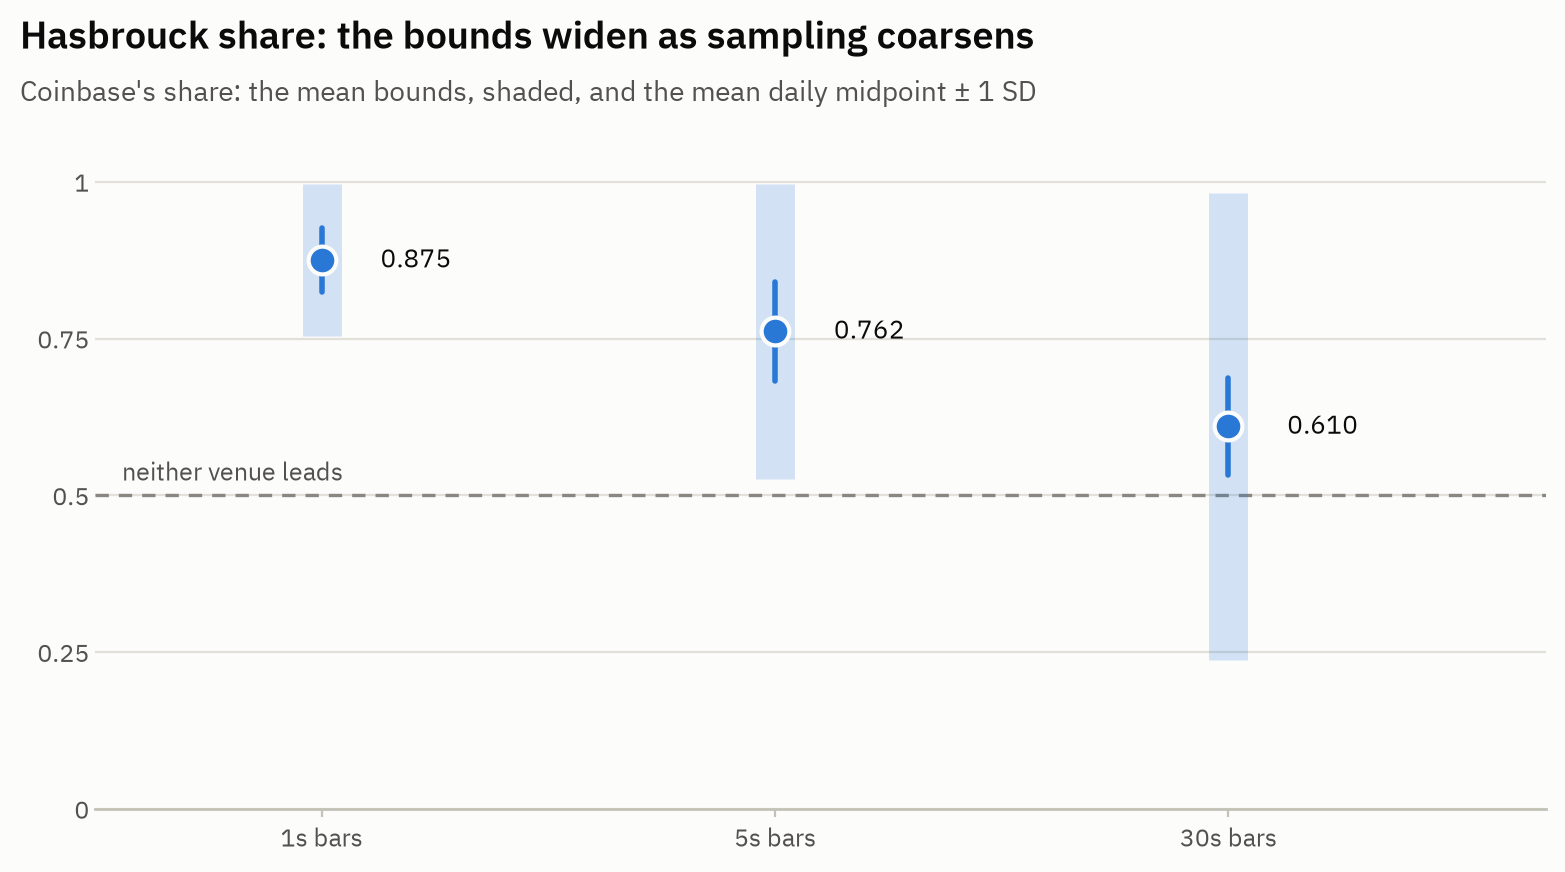

bars      mean bounds  width        midpoint  corr  lower bound below 0.5
  1s [0.754, 0.997]  0.243 0.875 +/- 0.051  0.46  0 of 20 days
  5s [0.527, 0.997]  0.471 0.762 +/- 0.079  0.69  8 of 20 days
 30s [0.237, 0.983]  0.746 0.610 +/- 0.077  0.89  18 of 20 days

crosstick's record, fitted across holes on every stride-th row: 1s [0.720, 0.997], 5s [0.498, 0.997], 30s [0.212, 0.985]


In [18]:
strides = (1, 5, 30)
by_stride = {s: [vecm(p, whole) for p, whole in unbroken(s).values()] for s in strides}

fig, ax = plt.subplots(figsize=(7.8, 4.4))
for i, fits in enumerate(by_stride.values()):
    bounds = np.array([f.bounds for f in fits])
    mids = bounds.mean(axis=1)
    ax.plot([i, i], [bounds[:, 0].mean(), bounds[:, 1].mean()], color=COINBASE, lw=14,
            alpha=0.2, solid_capstyle="butt", zorder=3)
    ax.plot([i, i], [mids.mean() - mids.std(), mids.mean() + mids.std()], color=COINBASE,
            lw=2, zorder=4)
    ax.plot([i], [mids.mean()], "o", color=COINBASE, ms=10, mec=SURFACE, mew=1.5, zorder=5)
    note(ax, i + 0.13, mids.mean(), f"{mids.mean():.3f}", va="center", fontsize=9.5, color=INK)
ax.axhline(0.5, color=MUTED, lw=1.2, ls=(0, (4, 3)), zorder=2)
note(ax, -0.44, 0.515, "neither venue leads", va="bottom")
ax.set_xticks(range(len(strides)), [f"{stride}s bars" for stride in strides])
ax.set_ylim(0, 1.02)
ax.set_xlim(-0.5, len(strides) - 0.3)
ax.set_yticks([0, 0.25, 0.5, 0.75, 1], ["0", "0.25", "0.5", "0.75", "1"])
ax.grid(axis="y")
headline(fig, "Hasbrouck share: the bounds widen as sampling coarsens",
         "Coinbase's share: the mean bounds, shaded, and the mean daily midpoint ± 1 SD",
         top=0.85, left=0.06, right=0.99, bottom=0.08)
plt.show()

print(f"{'bars':>4} {'mean bounds':>16} {'width':>6} {'midpoint':>15} {'corr':>5}  "
      f"lower bound below 0.5")
for stride, fits in by_stride.items():
    b = np.array([f.bounds for f in fits])
    mid = b.mean(axis=1)
    corr = np.mean([f.corr for f in fits])
    print(f"{stride:>3}s [{b[:, 0].mean():.3f}, {b[:, 1].mean():.3f}] "
          f"{(b[:, 1] - b[:, 0]).mean():6.3f} {mid.mean():.3f} +/- {mid.std():.3f} {corr:5.2f}  "
          f"{(b[:, 0] < 0.5).sum()} of {len(fits)} days")
print("\ncrosstick's record, fitted across holes on every stride-th row: " + ", ".join(
    f"{block['stride']}s [{np.mean([e['bounds'][0][0] for e in block['estimates']]):.3f}, "
    f"{np.mean([e['bounds'][0][1] for e in block['estimates']]):.3f}]"
    for block in real["infoshare"]))


# The text below quotes these.
quoted = {s: (np.array([f.bounds for f in fits]), np.mean([f.corr for f in fits]))
          for s, fits in by_stride.items()}
assert [f"[{b[:, 0].mean():.3f}, {b[:, 1].mean():.3f}] {c:.2f} {(b[:, 0] < 0.5).sum()}"
        for b, c in quoted.values()] == \
    ["[0.754, 0.997] 0.46 0", "[0.527, 0.997] 0.69 8", "[0.237, 0.983] 0.89 18"]
assert all(np.mean([e["bounds"][0][0] for e in block["estimates"]])
           < quoted[block["stride"]][0][:, 0].mean() for block in real["infoshare"])

The bounds widen as the sampling coarsens, from [0.754, 0.997] at one second, because more of
the venues' shocks land in the same bar: the shock correlation rises from 0.46 to 0.69 at five
seconds and 0.89 at thirty, and the days whose lower bound falls below one half go from 0 to 8
to 18 of 20. Over thirty seconds both venues have reacted to almost anything, so the data can
no longer say which reacted first, and a share quoted without its sampling interval is not an
answer. crosstick's record, fitted across holes, shows the same pattern, a little lower.

In [19]:
for lags in (5, 10, 20):
    b = np.array([vecm(p, whole, lags).bounds for p, whole in one.values()])
    print(f"{lags:>2} lags, one-second bars: bounds averaged over the days "
          f"[{b[:, 0].mean():.3f}, {b[:, 1].mean():.3f}]")


def adf_t(x, whole, lags=10):
    """Augmented Dickey-Fuller t-statistic, with a constant and `lags` lagged differences,
    skipping holes the way the fit does."""
    dx = np.diff(x)
    stretch = np.cumsum(~whole)
    t = np.arange(lags, len(dx))
    t = t[stretch[t - lags] == stretch[t + 1]]
    X = np.column_stack([x[t], *(dx[t - k] for k in range(1, lags + 1)), np.ones(len(t))])
    coef, *_ = np.linalg.lstsq(X, dx[t], rcond=None)
    resid = dx[t] - X @ coef
    var = resid @ resid / (len(t) - X.shape[1]) * np.linalg.inv(X.T @ X)[0, 0]
    return coef[0] / np.sqrt(var)


# Asymptotic Dickey-Fuller critical values with a constant (MacKinnon 1996). The basis
# imposes its cointegrating vector rather than estimating it, so they apply as they stand.
CRIT_1, CRIT_5 = -3.43, -2.86
basis = np.array([adf_t(p[:, 0] - p[:, 1], whole) for p, whole in one.values()])
levels = np.array([[adf_t(p[:, 0], whole), adf_t(p[:, 1], whole)] for p, whole in one.values()])
print(f"\nADF t-statistics over {len(one)} days; critical values {CRIT_1} (1%), {CRIT_5} (5%)")
print(f"  the basis, log Coinbase minus log Kraken: {basis.min():.1f} to {basis.max():.1f}")
print(f"  each venue's log price:                   {levels.min():.2f} to {levels.max():.2f}")
low_day, low_venue = np.unravel_index(levels.argmin(), levels.shape)
print(f"  below the 5% value in {(levels < CRIT_5).sum()} of {levels.size} tests, the lowest "
      f"{venues[low_venue].capitalize()} on {list(one)[low_day][5:]}; below the 1% value in "
      f"{(levels < CRIT_1).sum()}; chance alone would put {0.05 * levels.size:.0f} below the 5% value")
print(f"  the lowest: {levels.min():.3f}")
assert (basis < CRIT_1).all() and not (levels < CRIT_1).any()

# Gonzalo-Granger: Coinbase's weight is Kraken's pull over the two pulls combined. The pulls
# are signed as in the essay, each the share of the gap its own venue closes per second.
pulls = np.array([f.pulls for f in skipping.values()])
gg = pulls[:, 1] / pulls.sum(axis=1)
print(f"\nCoinbase's pull {pulls[:, 0].mean():.2%} a second on average, day-to-day SD "
      f"{pulls[:, 0].std(ddof=1):.2%}, below zero on {(pulls[:, 0] < 0).sum()} days; "
      f"Kraken's is {pulls[:, 1].mean() / pulls[:, 0].mean():.0f} times as large")
print(f"Gonzalo-Granger share, Coinbase: {gg.min():.2f} to {gg.max():.2f}, average "
      f"{gg.mean():.3f}, above 1 on {(gg > 1).sum()} days")


# The text below quotes these.
assert f"{basis.max():.1f} {(levels < CRIT_5).sum()}" == "-15.8 1"
assert f"{pulls[:, 0].mean():.2%} {pulls[:, 0].std(ddof=1):.2%} {(pulls[:, 0] < 0).sum()}" \
    == "0.27% 0.34% 4"
assert f"{gg.min():.2f} {gg.max():.2f} {gg.mean():.3f} {(gg > 1).sum()}" == "0.86 1.09 0.954 4"

 5 lags, one-second bars: bounds averaged over the days [0.762, 0.997]


10 lags, one-second bars: bounds averaged over the days [0.754, 0.997]


20 lags, one-second bars: bounds averaged over the days [0.763, 0.998]



ADF t-statistics over 20 days; critical values -3.43 (1%), -2.86 (5%)
  the basis, log Coinbase minus log Kraken: -44.4 to -15.8
  each venue's log price:                   -2.86 to 1.38
  below the 5% value in 1 of 40 tests, the lowest Coinbase on 07-15; below the 1% value in 0; chance alone would put 2 below the 5% value
  the lowest: -2.864

Coinbase's pull 0.27% a second on average, day-to-day SD 0.34%, below zero on 4 days; Kraken's is 17 times as large
Gonzalo-Granger share, Coinbase: 0.86 to 1.09, average 0.954, above 1 on 4 days


The lag order was set at ten to span the forecast's five-second horizon, not chosen by a
criterion. Five or twenty lags move the averaged bounds by less than a hundredth, to [0.762,
0.997] and [0.763, 0.998].

The model assumes each log price wanders without settling while the gap between them keeps
coming back, with the cointegrating vector imposed as (1, -1). Augmented Dickey-Fuller tests,
skipping holes, agree. They reject a unit root in the gap at 1% on all 20 days, with
t-statistics no higher than -15.8 against a critical value of -3.43, and in the log prices at
1% in none of the 40 day-by-venue tests and at 5% in only 1, fewer than the 2 that chance alone
would give.

**The Gonzalo-Granger share is computed but not headlined.** It divides Kraken's pull by the
two pulls combined, and Coinbase's pull is small and noisy, averaging 0.27% a second with a
day-to-day spread of 0.34%. On the 4 days it dips below zero the share exceeds 1. Over the 20
days the share runs from 0.86 to 1.09 and averages 0.954, pointing the same way as Hasbrouck's
bounds, but a value above 1 cannot be read as a share.

## 11. Timing: whose clock?

Every price in this study is stamped when it reached our capture machine, which folds in how
long each venue's updates take to arrive: if Kraken's take longer, Coinbase starts every second
slightly ahead. This section measures that head start, establishes what each exchange's own
stamp marks, and refits the information share and the jump study without it. The measurements
come from crosstick's lake: `scripts/extract_clocks.py` read both stamps of every book update
and trade, and `scripts/export_clocks.py` published the result only after the arrival clock,
rebuilt from the same tables, matched the published prices bit for bit.

In [20]:
clocks = json.loads((DATA / "clocks.json").read_text(encoding="utf-8"))
delay = {venue: np.array([d["book_delay_ms"]["p50"] for d in by_day.values()])
         for venue, by_day in clocks["venues"].items()}
print("median time from a book update's own stamp to its arrival here")
for venue, ms in delay.items():
    print(f"  {venue:9s} {np.median(ms):5.1f} ms on the median day, {ms.min():.1f} to {ms.max():.1f} by day")
extra = delay["kraken"] - delay["coinbase"]
print(f"  Kraken's arrive {np.median(extra):.0f} ms after Coinbase's on the median day, "
      f"{extra.min():.0f} to {extra.max():.0f} ms by day")

trade = {venue: np.array([d["trade_delay_ms"]["p50"] for d in by_day.values()])
         for venue, by_day in clocks["venues"].items()}
print("\nmedian time from a trade's own stamp to its arrival here")
for venue, ms in trade.items():
    print(f"  {venue:9s} {np.median(ms):5.1f} ms on the median day, {ms.min():.1f} to {ms.max():.1f} by day")
late = trade["coinbase"] - trade["kraken"]
print(f"  timed from the trade, Coinbase's arrive {np.median(late):.0f} ms after Kraken's on the median "
      f"day, {late.min():.0f} to {late.max():.0f} ms by day")

# A trade's side here is the taker's. crosstick records Coinbase's as the side of the resting
# order it filled, so `extract_clocks.py` flips it and holds the result to the book.
print("\nthe side that took liquidity, held to the book: on every day, trades taken as")
for venue, by_day in clocks["venues"].items():
    q = [d["quote_test"] for d in by_day.values()]
    print(f"  {venue:9s} buys printed above the mid at least {min(t['buys_above_mid'] for t in q):.1%} "
          f"of the time, sells below it at least {min(t['sells_below_mid'] for t in q):.1%}")

print("\nwhen a trade takes out the best price, does the book update carry the trade's own stamp?")
for venue, by_day in clocks["venues"].items():
    matched = sum(d["stamp_test"]["matched"] for d in by_day.values())
    equal = sum(d["stamp_test"]["equal"] for d in by_day.values())
    after = np.median([d["stamp_test"]["gap_ms"]["p50"] for d in by_day.values()])
    print(f"  {venue:9s} identical on {equal / matched:5.1%} of {matched:,} such moves, stamped a "
          f"median {after:.0f} ms after the trade on the median day")

# The text below quotes these.
tests = {v: [d["stamp_test"] for d in by_day.values()] for v, by_day in clocks["venues"].items()}
assert sum(t["equal"] for t in tests["coinbase"]) == 0
kraken_equal = sum(t["equal"] for t in tests["kraken"]) / sum(t["matched"] for t in tests["kraken"])
assert f"{np.median(extra):.0f} {extra.min():.0f} {extra.max():.0f} {kraken_equal:.1%}" == "43 38 50 70.1%"
coinbase_after = np.median([t["gap_ms"]["p50"] for t in tests["coinbase"]])
assert f"{sum(t['matched'] for t in tests['coinbase']):,} {coinbase_after:.0f}" == "907,196 86"
assert f"{np.median(trade['coinbase']):.0f} {np.median(trade['kraken']):.0f} {np.median(delay['kraken']):.0f}" == \
    "108 68 68"
assert f"{np.median(late):.0f} {late.min():.0f} {late.max():.0f}" == "40 34 46"

median time from a book update's own stamp to its arrival here
  coinbase   24.4 ms on the median day, 17.4 to 36.6 by day
  kraken     68.1 ms on the median day, 56.2 to 77.4 by day
  Kraken's arrive 43 ms after Coinbase's on the median day, 38 to 50 ms by day

median time from a trade's own stamp to its arrival here
  coinbase  107.6 ms on the median day, 97.0 to 118.6 by day
  kraken     68.5 ms on the median day, 55.2 to 77.2 by day
  timed from the trade, Coinbase's arrive 40 ms after Kraken's on the median day, 34 to 46 ms by day

the side that took liquidity, held to the book: on every day, trades taken as
  coinbase  buys printed above the mid at least 70.4% of the time, sells below it at least 77.3%
  kraken    buys printed above the mid at least 99.8% of the time, sells below it at least 99.7%

when a trade takes out the best price, does the book update carry the trade's own stamp?
  coinbase  identical on  0.0% of 907,196 such moves, stamped a median 86 ms after the trade on

Kraken's book updates reach us 43 ms after Coinbase's on the median day, and 38 to 50 ms after
on every day, each measured from the venue's own stamp. That is a head start only if the two
stamps mark the same moment, and they do not. When a trade takes out the best price, the book
update that removes the price should carry the trade's own stamp if both mark the same event in
the matching engine. On Kraken they are identical on 70.1% of 150,464 such moves: Kraken stamps
the change in its book. On Coinbase, with its trade sides flipped as section 2 describes and
held to the book in the cell above, they are identical on none of 907,196, and the book update
is stamped a median 86 ms after the trade: Coinbase stamps the sending, as its documentation
says.

Timed from the trade, the head start runs the other way. A Coinbase trade reaches us 108 ms
after its own stamp on the median day and a Kraken trade 68 ms, so Coinbase's news arrives 40
ms after Kraken's, and 34 to 46 ms after on every day. If the two exchanges' clocks agree, the
arrival clock favours Kraken, and the exchanges' own stamps, which put each Kraken update at
its book change and each Coinbase update at the later send, favour it more. A second check
needs no stamps at all: move Kraken's prices earlier by a fixed amount, as if every update had
happened that long before it reached us.

In [21]:
retimed = pl.read_parquet(DATA / "prices_retimed.parquet")


def timed(*series):
    """The published prices with each named re-timed series swapped in for its venue."""
    panel = prices
    for name in series:
        venue = name.split("_")[0]
        swap = retimed.filter(pl.col("series") == name).select("date", "ts_ns", "mid")
        panel = (panel.join(swap, on=["date", "ts_ns"], how="left")
                 .with_columns(pl.coalesce("mid", f"{venue}_mid").alias(f"{venue}_mid"))
                 .drop("mid"))
    return panel.sort("ts_ns")


def catch_up(panel):
    """The essay's jump study: Kraken's move ten seconds after a Coinbase jump of 2 bp or
    more, as a share of Coinbase's."""
    ts, day = panel["ts_ns"].to_numpy(), panel["date"].to_numpy()
    logp = np.log(panel.select(["coinbase_mid", "kraken_mid"]).to_numpy()) * 1e4
    follows = np.r_[False, (np.diff(ts) == 1_000_000_000) & (day[1:] == day[:-1])]
    stretch = np.cumsum(~follows)
    move = np.r_[np.nan, np.diff(logp[:, 0])]
    at = np.flatnonzero(follows & (np.abs(move) >= 2.0))
    at = at[(at >= 10) & (at + 15 < len(logp))]
    at = at[stretch[at - 10] == stretch[at + 15]]
    ten = (logp[at + 10] - logp[at - 1]) * np.sign(move[at])[:, None]
    return ten[:, 1].mean() / ten[:, 0].mean()


def measure(panel, step=1):
    """Coinbase's daily Hasbrouck bounds and both venues' daily pulls, on bars `step`
    seconds apart, skipping holes as in section 9."""
    fits = [vecm(p, whole) for p, whole in unbroken(step, panel).values()]
    return np.array([f.bounds for f in fits]), np.array([f.pulls for f in fits])


shifts = clocks["shifts_ms"]
clock_rows = {"on arrival, as published": prices,
              "on each exchange's own stamp": timed("coinbase_exchange", "kraken_exchange")}
clock_rows |= {f"Kraken shifted {s} ms earlier": timed(f"kraken_plus_{s}ms") for s in shifts}
results = {}
print(f"{'prices timed':30s} {'Coinbase share, 1s':>18s} {'lower < 0.5':>12s} "
      f"{'Kraken pull / Coinbase':>23s} {'catch-up':>9s}")
for name, panel in clock_rows.items():
    bounds, pulls = measure(panel)
    ratio = pulls[:, 1].mean() / pulls[:, 0].mean()
    results[name] = (bounds.mean(axis=0), ratio, catch_up(panel))
    share = f"[{bounds[:, 0].mean():.3f}, {bounds[:, 1].mean():.3f}]"
    below = f"{(bounds[:, 0] < 0.5).sum()} of 20"
    print(f"{name:30s} {share:>18s} {below:>12s} {f'{ratio:.0f}x':>23s} {results[name][2]:>9.0%}")

# The published row is the essay's: the same bounds, pull ratio and catch-up it quotes.
published = results["on arrival, as published"]
assert f"[{published[0][0]:.3f}, {published[0][1]:.3f}] {published[1]:.0f} {published[2]:.0%}" \
    == "[0.754, 0.997] 17 91%"


def quoted(name):
    (low, high), ratio, caught = results[name]
    return f"[{low:.3f}, {high:.3f}] {ratio:.0f} {caught:.0%}"


# The text below quotes these.
assert quoted("on each exchange's own stamp") == "[0.733, 0.996] 12 90%"
assert quoted("Kraken shifted 200 ms earlier") == "[0.683, 0.987] 6 85%"
exchange = clock_rows["on each exchange's own stamp"]
for stride in (5, 30):
    on_stamp, as_published = measure(exchange, stride)[0], measure(prices, stride)[0]
    print(f"\n{stride}s bars: [{on_stamp[:, 0].mean():.3f}, {on_stamp[:, 1].mean():.3f}] on the "
          f"exchanges' stamps, [{as_published[:, 0].mean():.3f}, {as_published[:, 1].mean():.3f}] "
          f"as published", end="")
print()

prices timed                   Coinbase share, 1s  lower < 0.5  Kraken pull / Coinbase  catch-up


on arrival, as published           [0.754, 0.997]      0 of 20                     17x       91%


on each exchange's own stamp       [0.733, 0.996]      0 of 20                     12x       90%


Kraken shifted 20 ms earlier       [0.745, 0.997]      0 of 20                     15x       91%


Kraken shifted 40 ms earlier       [0.738, 0.996]      0 of 20                     13x       90%


...

Kraken shifted 100 ms earlier      [0.717, 0.994]      1 of 20                      9x       89%


Kraken shifted 150 ms earlier      [0.697, 0.991]      1 of 20                      7x       87%


Kraken shifted 200 ms earlier      [0.683, 0.987]      2 of 20                      6x       85%



5s bars: [0.524, 0.997] on the exchanges' stamps, [0.527, 0.997] as published


30s bars: [0.238, 0.983] on the exchanges' stamps, [0.237, 0.983] as published


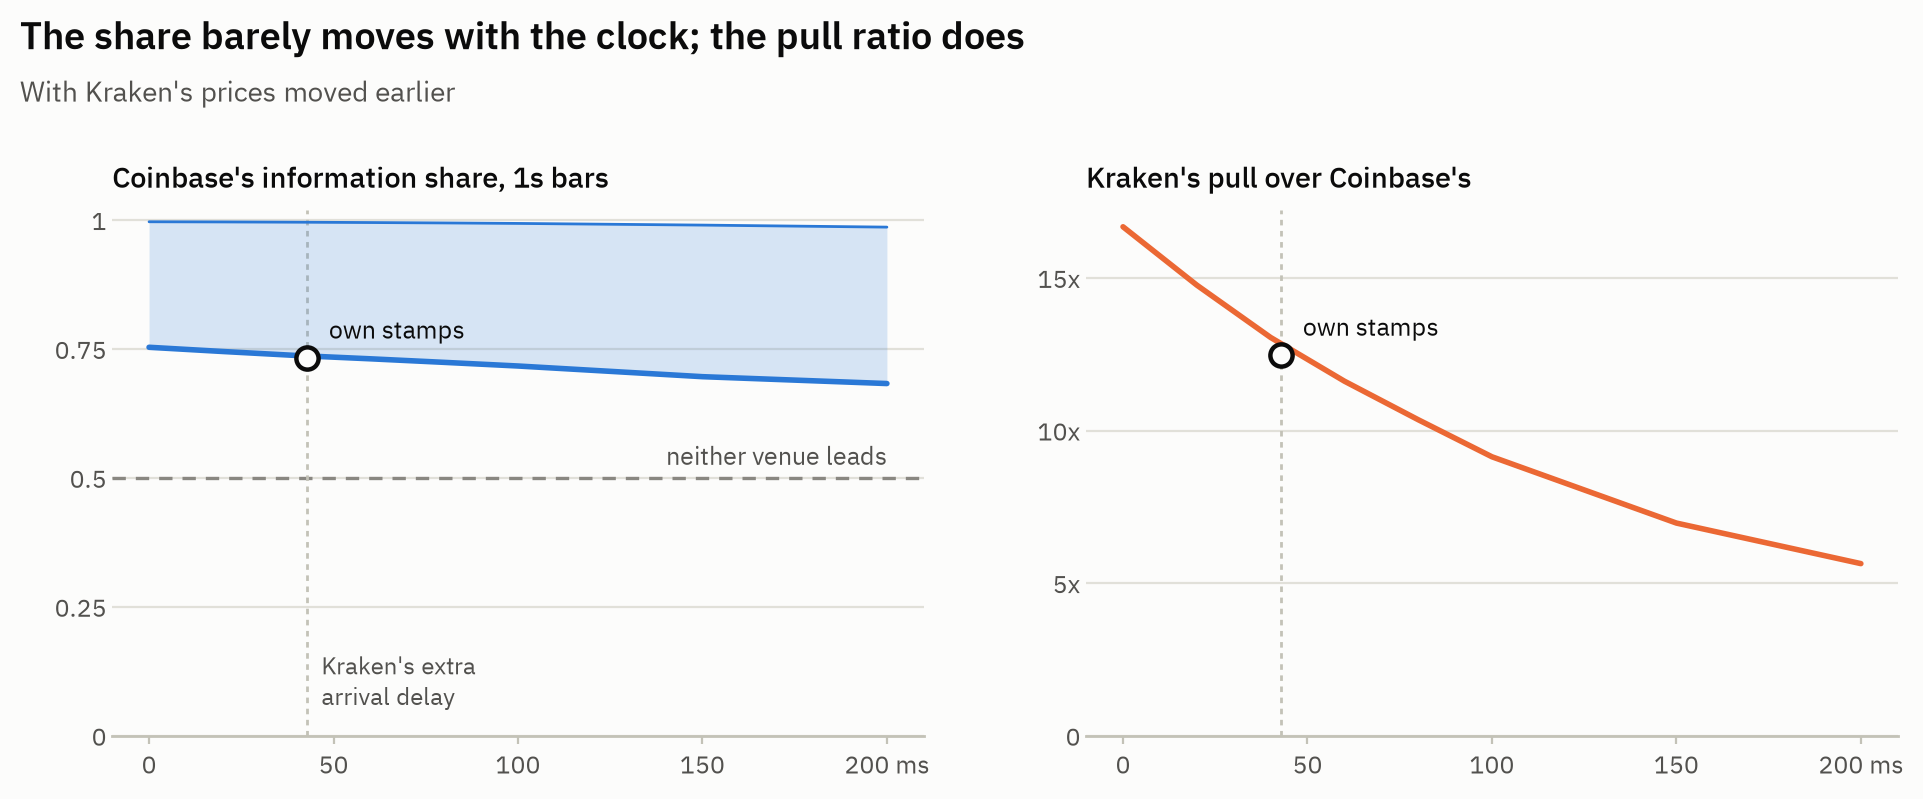

In [22]:
x = [0, *shifts]
sweep = [results["on arrival, as published"],
         *(results[f"Kraken shifted {s} ms earlier"] for s in shifts)]
stamp = results["on each exchange's own stamp"]
gap_ms = np.median(extra)

fig, (left, right) = plt.subplots(1, 2, figsize=(9.6, 4.0))
low, high = np.array([b for b, _, _ in sweep]).T
left.fill_between(x, low, high, color=COINBASE, alpha=0.18, lw=0, zorder=2)
left.plot(x, low, color=COINBASE, lw=2, zorder=3)
left.plot(x, high, color=COINBASE, lw=1, zorder=3)
left.axhline(0.5, color=MUTED, lw=1.2, ls=(0, (4, 3)), zorder=1)
note(left, x[-1], 0.515, "neither venue leads", ha="right", va="bottom")
left.set_ylim(0, 1.02)
left.set_yticks([0, 0.25, 0.5, 0.75, 1], ["0", "0.25", "0.5", "0.75", "1"])
left.set_title("Coinbase's information share, 1s bars")

right.plot(x, [r for _, r, _ in sweep], color=KRAKEN, lw=2, zorder=3)
right.set_ylim(0, None)
right.yaxis.set_major_locator(mpl.ticker.MultipleLocator(5))
right.yaxis.set_major_formatter(lambda v, _: f"{v:.0f}x" if v else "0")
right.set_title("Kraken's pull over Coinbase's")

# Each exchange's own stamp, drawn where Kraken's extra arrival delay puts it.
for ax, y in ((left, stamp[0][0]), (right, stamp[1])):
    ax.axvline(gap_ms, color=AXIS, lw=1, ls=(0, (2, 2)), zorder=1)
    ax.plot([gap_ms], [y], "o", mfc=SURFACE, mec=INK, mew=1.6, ms=8, zorder=4)
    ax.annotate("own stamps", (gap_ms, y), xytext=(8, 5), textcoords="offset points",
                va="bottom", fontsize=9, color=INK)
    ax.set_xticks([0, 50, 100, 150, 200], ["0", "50", "100", "150", "200 ms"])
    ax.grid(axis="y")
note(left, gap_ms + 4, 0.06, "Kraken's extra\narrival delay", fontsize=8.5)
headline(fig, "The share barely moves with the clock; the pull ratio does",
         "With Kraken's prices moved earlier", top=1.05, left=0.06, right=0.99, bottom=0.08,
         wspace=0.2)
plt.show()

On the exchanges' own stamps, Coinbase's share averages [0.733, 0.996] against [0.754, 0.997]
as published, its lower bound stays above one half on all 20 days, and Kraken covers 90% of a
Coinbase jump within ten seconds against 91%. At five- and thirty-second bars the stamps give
[0.524, 0.997] and [0.238, 0.983], against [0.527, 0.997] and [0.237, 0.983]. Shifting Kraken's
prices 200 ms earlier, more than four times its extra delay, still leaves Coinbase's share at
[0.683, 0.987], its lower bound below one half on 2 of 20 days, and Kraken covering 85% of a
jump. The lead is not an artefact of where we listened from.

What the clock does move is the ratio of the pulls: Kraken pulls 17 times as hard as Coinbase
on arrival, 12 times on the exchanges' stamps and 6 times at a 200 ms shift. Coinbase's pull is
close to zero, so the ratio divides by a small number and swings with any nudge. That Kraken
does nearly all the closing holds on every clock; the essay's 17 is the arrival clock's.

## 12. Time of day

Most people trading bitcoin keep office hours, so a lead measured over whole days could average
hours in which Coinbase leads strongly with hours in which it does not lead at all. We split
each day into three eight-hour blocks of UTC time, roughly the working days of Asia, Europe and
the Americas, and in every block fit the error-correction model, skipping holes, and rerun the
jump study. We also split the days by whether the US stock market opened: it did on 11 of the
20, and not on the other 9, the weekends and 07-03, when US exchanges closed for Independence
Day.

In [23]:
from datetime import date

from research.infoshare import DEFAULT_LAGS, MIN_ROWS, OBS_PER_PARAMETER

dates = real["spec"]["dates"]
# 07-03 was a Friday, but US stock exchanges closed for Independence Day.
stocks_open = {d: date.fromisoformat(d).weekday() < 5 and d != "2026-07-03" for d in dates}
DRAWS = np.random.default_rng(0).integers(0, len(dates), (2000, len(dates)))
# How often each day appears in each resample, so the intervals below keep whole days together.
REPEATS = np.stack([np.bincount(draw, minlength=len(dates)) for draw in DRAWS])


def by_block(panel, hours):
    """Tag each bar with its block of the UTC day, and its day with whether US stocks traded.
    The midnight bar that ends a date stays in that date's last block."""
    day0 = pl.col("date").str.to_date().cast(pl.Datetime("ns")).cast(pl.Int64)
    seconds = (pl.col("ts_ns") - day0) // 1_000_000_000
    block = pl.min_horizontal(seconds // (hours * 3600), 24 // hours - 1)
    return panel.with_columns(block=block, stocks=pl.col("date").replace_strict(stocks_open))


def floor(hours):
    """crosstick's floor for a day's estimate, scaled to the part of the day a block covers
    as `min_rows_for` scales it for a coarser stride, and never under its hard floor of 20
    observations per fitted coefficient."""
    return max(MIN_ROWS * hours // 24, OBS_PER_PARAMETER * (2 * DEFAULT_LAGS + 2))


def fit_blocks(panel, hours):
    """Coinbase's bounds, both pulls and the shock correlation, per day and block."""
    rows = []
    for (d, b, open_), g in by_block(panel, hours).group_by(["date", "block", "stocks"],
                                                          maintain_order=True):
        if g.height < floor(hours):
            continue
        whole = np.r_[False, np.diff(g["ts_ns"].to_numpy()) == 1_000_000_000]
        f = vecm(np.log(g.select(["coinbase_mid", "kraken_mid"]).to_numpy()), whole)
        rows.append({"date": d, "block": b, "stocks": open_, "low": f.bounds[0],
                     "high": f.bounds[1], "corr": f.corr,
                     "coinbase_pull": f.pulls[0], "kraken_pull": f.pulls[1]})
    return pl.DataFrame(rows)


def jump_moves(panel, hours):
    """The essay's jump study, one row per Coinbase jump: both venues' moves in the jump's
    own second and over the ten seconds from the second before, signed so a follow is
    positive. Also the bars each block holds."""
    panel = by_block(panel, hours)
    ts, day = panel["ts_ns"].to_numpy(), panel["date"].to_numpy()
    logp = np.log(panel.select(["coinbase_mid", "kraken_mid"]).to_numpy()) * 1e4
    follows = np.r_[False, (np.diff(ts) == 1_000_000_000) & (day[1:] == day[:-1])]
    stretch = np.cumsum(~follows)
    move = np.r_[np.nan, np.diff(logp[:, 0])]
    at = np.flatnonzero(follows & (np.abs(move) >= 2.0))
    at = at[(at >= 10) & (at + 15 < len(logp))]
    at = at[stretch[at - 10] == stretch[at + 15]]
    sign = np.sign(move[at])[:, None]
    now, ten = (logp[at] - logp[at - 1]) * sign, (logp[at + 10] - logp[at - 1]) * sign
    moves = pl.DataFrame({"date": day[at], "block": panel["block"].to_numpy()[at],
                          "stocks": panel["stocks"].to_numpy()[at],
                          "coinbase_now": now[:, 0], "kraken_now": now[:, 1],
                          "coinbase_ten": ten[:, 0], "kraken_ten": ten[:, 1]})
    return moves, panel.group_by("date", "block", "stocks").len("bars")


def daily(frame, value):
    """`value` summed by day, in the order of `dates`, so a resample is a matrix product."""
    sums = dict(frame.group_by("date").agg(value).iter_rows())
    return np.array([sums.get(d, 0.0) for d in dates])


def share(moves, of):
    """Kraken's move as a share of Coinbase's, `of` 'now' or 'ten', with its interval."""
    k, c = daily(moves, pl.col(f"kraken_{of}").sum()), daily(moves, pl.col(f"coinbase_{of}").sum())
    return k.sum() / c.sum(), np.percentile(REPEATS @ k / (REPEATS @ c), [2.5, 97.5])


def mean_low(fits):
    """The lower bound averaged over blocks, with its interval."""
    s, n = daily(fits, pl.col("low").sum()), daily(fits, pl.len().cast(pl.Float64))
    return s.sum() / n.sum(), np.percentile(REPEATS @ s / (REPEATS @ n), [2.5, 97.5])


ROWS = {f"{8 * b:02d}-{8 * b + 8:02d} UTC": pl.col("block") == b for b in range(3)}
ROWS |= {"stock days": pl.col("stocks"), "other days": ~pl.col("stocks")}


def summarise(panel):
    """Every measure for each eight-hour block, and for days US stocks did and did not trade."""
    fits = fit_blocks(panel, 8)
    moves, bars = jump_moves(panel, 8)
    out = {}
    for name, keep in ROWS.items():
        f, m = fits.filter(keep), moves.filter(keep)
        out[name] = {"blocks": f.height, "below": int((f["low"] < 0.5).sum()),
                     "per_hour": m.height / bars.filter(keep)["bars"].sum() * 3600,
                     "corr": f["corr"].mean(), "low": mean_low(f), "high": f["high"].mean(),
                     "coinbase_pull": f["coinbase_pull"].mean(),
                     "kraken_pull": f["kraken_pull"].mean(),
                     "now": share(m, "now"), "ten": share(m, "ten")}
    return fits, bars, out

In [24]:
fits, bars, blocks = summarise(prices)
held = {(d, b): n for d, b, _, n in bars.iter_rows()}
fitted = set(fits.select("date", "block").iter_rows())
short = [(d, b) for d in dates for b in range(3) if (d, b) not in fitted]
print(f"{fits.height} of {3 * len(dates)} blocks have the {floor(8):,} one-second bars a fit needs; "
      "short of it: " + ", ".join(f"{d[5:]} {8 * b:02d}-{8 * b + 8:02d} UTC with "
                                  f"{held.get((d, b), 0):,}" for d, b in short))
traded = sum(stocks_open.values())
print(f"US stocks traded on {traded} of the {len(dates)} days and not on the other "
      f"{len(dates) - traded}; intervals are 95%, over {len(DRAWS):,} resamples of whole days\n")

print(f"{'':11s} {'blocks':>6s} {'jumps/h':>8s} {'corr':>5s} {'Coinbase share, 1s':>19s} "
      f"{'lower < 0.5':>11s}   {'pull a second':>17s}")
print(f"{'':11s} {'':6s} {'':8s} {'':5s} {'':19s} {'':11s}   {'Coinbase':>8s} {'Kraken':>8s}")
for name, r in blocks.items():
    bounds, below = f"[{r['low'][0]:.3f}, {r['high']:.3f}]", f"{r['below']} of {r['blocks']}"
    print(f"{name:11s} {r['blocks']:>6d} {r['per_hour']:>8.0f} {r['corr']:>5.2f} {bounds:>19s} "
          f"{below:>11s}   {r['coinbase_pull']:>8.2%} {r['kraken_pull']:>8.2%}")

print(f"\n{'':11s} {'lower bound':>22s} {'Kraken, same second':>24s} {'Kraken, ten seconds':>24s}")
for name, r in blocks.items():
    (low, (l0, l1)), (now, (n0, n1)), (ten, (t0, t1)) = r["low"], r["now"], r["ten"]
    print(f"{name:11s} {low:>8.3f} [{l0:.3f}, {l1:.3f}] {now:>9.0%} [{n0:.0%}, {n1:.0%}] "
          f"{ten:>9.0%} [{t0:.0%}, {t1:.0%}]")

# The text below quotes these.
table = list(blocks.values())
assert f"{fits.height} {floor(8)} {traded} {[held.get(s, 0) for s in short]}" == \
    "58 1666 11 [0, 1075]"
assert min(r["low"][0] for r in table) > 0.5
assert [f"{r['per_hour']:.0f} {r['low'][0]:.3f} {r['corr']:.2f}" for r in table] == \
    ["38 0.810 0.40", "78 0.742 0.47", "44 0.733 0.46", "76 0.733 0.47", "25 0.798 0.40"]
spread = [f"{f(r[k][0] for r in table):.0%}" for k in ("now", "ten") for f in (min, max)]
assert spread == ["48%", "50%", "88%", "92%"]

58 of 60 blocks have the 1,666 one-second bars a fit needs; short of it: 07-06 16-24 UTC with 0, 07-26 16-24 UTC with 1,075
US stocks traded on 11 of the 20 days and not on the other 9; intervals are 95%, over 2,000 resamples of whole days

            blocks  jumps/h  corr  Coinbase share, 1s lower < 0.5       pull a second
                                                                    Coinbase   Kraken
00-08 UTC       20       38  0.40      [0.810, 0.995]     0 of 20      0.19%    4.69%
08-16 UTC       20       78  0.47      [0.742, 0.994]     1 of 20      0.27%    4.82%
16-24 UTC       18       44  0.46      [0.733, 0.994]     0 of 18      0.47%    4.88%
stock days      32       76  0.47      [0.733, 0.996]     1 of 32      0.39%    5.93%
other days      26       25  0.40      [0.798, 0.993]     0 of 26      0.21%    3.39%

                       lower bound      Kraken, same second      Kraken, ten seconds
00-08 UTC      0.810 [0.773, 0.845]       49% [46%, 51%]       92% [87%

A block is fitted when it has at least 1,666 one-second bars, crosstick's floor for a day
scaled to a third of one, which keeps 58 of the 60. Coinbase leads in every block: the lower
bound of its share averages above one half in each, and in every row Kraken makes 48% to 50% of
a Coinbase jump in the jump's own second and 88% to 92% within ten seconds.

Two things vary. The market is busier from 08 to 16 UTC, with 78 Coinbase jumps an hour against
38 and 44 in the other blocks, and on days US stocks trade, with 76 against 25. And Coinbase's
lower bound is 0.810 from 00 to 08 UTC against 0.742 and 0.733 later, and 0.733 on stock-market
days against 0.798 on others: lower where the shock correlation is higher, 0.47 and 0.46
against 0.40.

In [25]:
# How much of the lower bound the shock correlation accounts for, and what it leaves in
# each block. The line is refitted on every resample of the days.
corr, low = fits["corr"].to_numpy(), fits["low"].to_numpy()
block, stock = fits["block"].to_numpy(), fits["stocks"].to_numpy()
X = np.column_stack([np.ones_like(corr), corr])
(intercept, slope), *_ = np.linalg.lstsq(X, low, rcond=None)
left = low - X @ [intercept, slope]
r2 = 1 - left.var() / low.var()


def mean_left(resid, w, keep):
    return np.average(resid[keep], weights=w[keep])


gaps = {f"{8 * k:02d}-{8 * k + 8:02d} UTC": lambda r, w, k=k: mean_left(r, w, block == k)
        for k in range(3)}
gaps["stock days less other days"] = lambda r, w: mean_left(r, w, stock) - mean_left(r, w, ~stock)
draws = {name: [] for name in gaps}
for w in REPEATS[:, [dates.index(d) for d in fits["date"]]].astype(float):
    coef, *_ = np.linalg.lstsq(X * np.sqrt(w)[:, None], low * np.sqrt(w), rcond=None)
    for name, stat in gaps.items():
        draws[name].append(stat(low - X @ coef, w))

print(f"over the {len(low)} blocks, Coinbase's lower bound = {intercept:.2f} {slope:+.2f} x the "
      f"shock correlation, which accounts for {r2:.0%} of its variation")
print("what the line leaves, on average:")
unweighted = np.ones_like(left)
bands = {name: np.percentile(draws[name], [2.5, 97.5]) for name in gaps}
for name, stat in gaps.items():
    lo, hi = bands[name]
    print(f"  {name:27s} {stat(left, unweighted):+.3f}  [{lo:+.3f}, {hi:+.3f}]")
widest = np.abs(list(bands.values())).max()
print(f"  every interval contains zero: {all(lo < 0 < hi for lo, hi in bands.values())}, "
      f"and lies within {widest:.3f} of it")

odd = int(np.argmin(low))
print(f"\nthe lowest block: {fits['date'][odd][5:]} {8 * block[odd]:02d}-{8 * block[odd] + 8:02d} UTC, "
      f"lower bound {low[odd]:.3f}, shock correlation {corr[odd]:.2f}")

_, _, on_stamps = summarise(timed("coinbase_exchange", "kraken_exchange"))
moved = {k: max(abs(on_stamps[n][k][0] - blocks[n][k][0]) for n in blocks) for k in ("low", "ten")}
print(f"on the exchanges' own stamps, no row of the table moves its lower bound by more than "
      f"{moved['low']:.3f} or its ten-second share by more than {moved['ten']:.1%}")

# The text below quotes these.
assert f"{r2:.0%} {widest:.3f}" == "82% 0.032"
assert [f"{stat(left, unweighted):+.3f}" for stat in list(gaps.values())[:3]] == \
    ["+0.002", "+0.010", "-0.013"]
assert abs(gaps["stock days less other days"](left, unweighted)) < 0.0005
assert all(lo < 0 < hi for lo, hi in bands.values())
assert f"{fits['date'][odd]} {block[odd]} {low[odd]:.3f} {corr[odd]:.2f}" == \
    "2026-06-29 1 0.457 0.67"
assert corr[odd] == corr.max()
assert f"{moved['low']:.3f} {moved['ten']:.1%}" == "0.025 1.7%"

over the 58 blocks, Coinbase's lower bound = 1.21 -1.03 x the shock correlation, which accounts for 82% of its variation
what the line leaves, on average:
  00-08 UTC                   +0.002  [-0.015, +0.019]
  08-16 UTC                   +0.010  [-0.006, +0.026]
  16-24 UTC                   -0.013  [-0.032, +0.001]
  stock days less other days  +0.000  [-0.028, +0.030]
  every interval contains zero: True, and lies within 0.032 of it

the lowest block: 06-29 08-16 UTC, lower bound 0.457, shock correlation 0.67


on the exchanges' own stamps, no row of the table moves its lower bound by more than 0.025 or its ten-second share by more than 1.7%


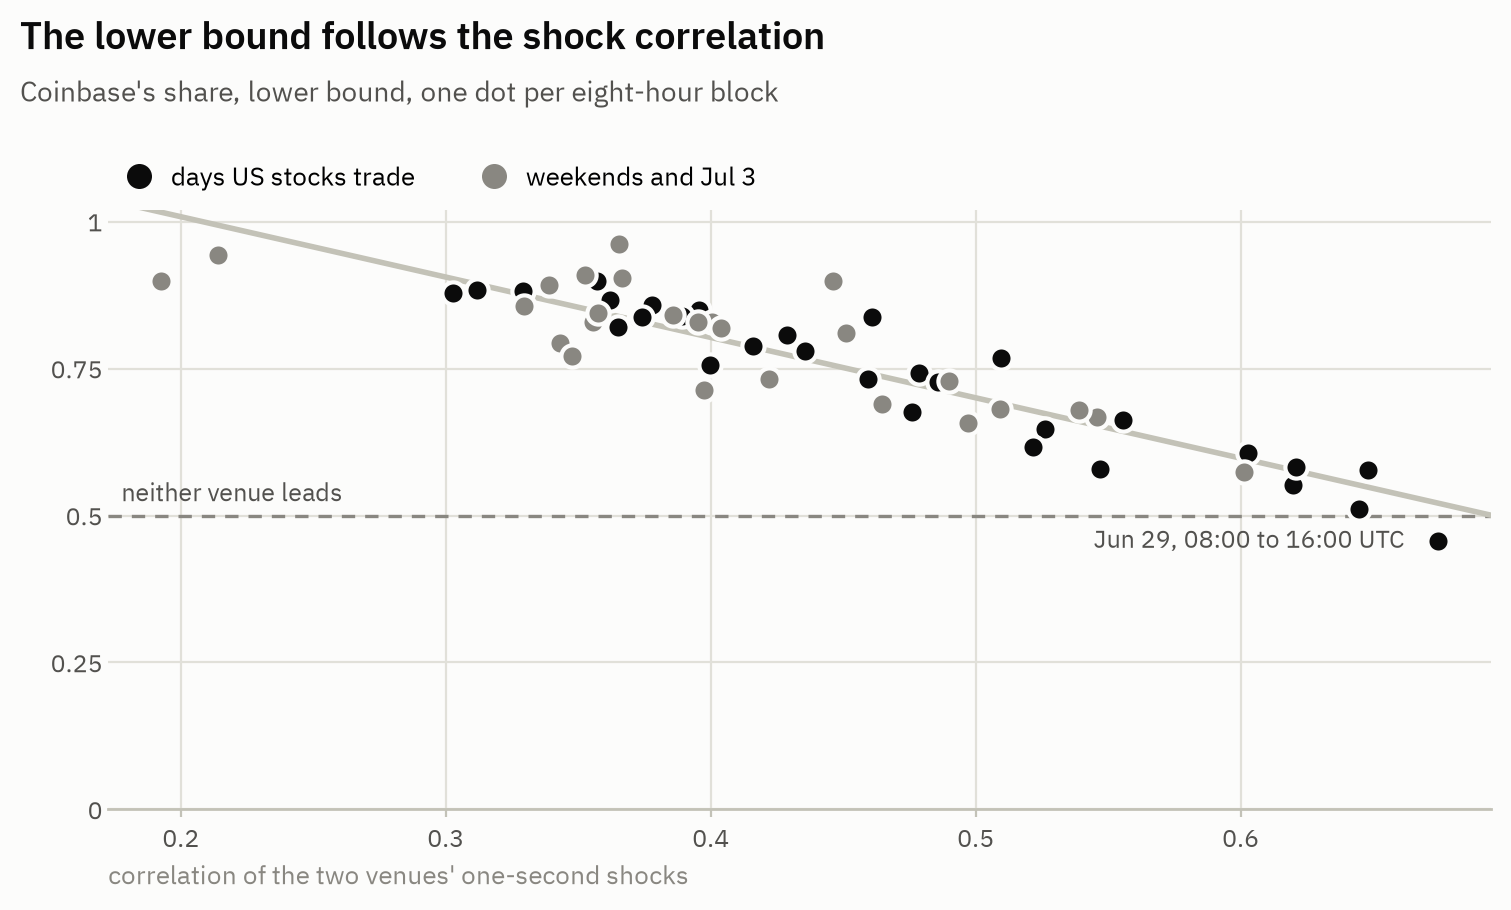

In [26]:
fig, ax = plt.subplots(figsize=(7.6, 4.6))
span = np.array([corr.min() - 0.02, corr.max() + 0.02])
ax.plot(span, intercept + slope * span, color=AXIS, lw=2, zorder=2)
groups = ((True, INK, "days US stocks trade"), (False, MUTED, "weekends and Jul 3"))
for open_, color, label in groups:
    keep = stock == open_
    ax.plot(corr[keep], low[keep], "o", color=color, mec=SURFACE, mew=1.5, ms=8, zorder=3)
ax.axhline(0.5, color=MUTED, lw=1.2, ls=(0, (4, 3)), zorder=1)
note(ax, span[0] + 0.005, 0.515, "neither venue leads", va="bottom")
first, hour = day_labels([fits["date"][odd]])[0], 8 * block[odd]
ax.annotate(f"{first}, {hour:02d}:00 to {hour + 8:02d}:00 UTC", (corr[odd], low[odd]),
            xytext=(-12, 0), textcoords="offset points", ha="right", va="center", fontsize=9,
            color=INK2)
ax.set_xlim(*span)
ax.set_ylim(0, 1.02)
ax.set_yticks([0, 0.25, 0.5, 0.75, 1], ["0", "0.25", "0.5", "0.75", "1"])
ax.set_xlabel("correlation of the two venues' one-second shocks", loc="left")
ax.grid()
ax.legend([plt.Line2D([], [], color=c, marker="o", ls="", ms=8) for _, c, _ in groups],
          [label for _, _, label in groups], loc="lower left", bbox_to_anchor=(-0.01, 1.0),
          ncol=2, handletextpad=0.2, fontsize=9.5, borderaxespad=0.3)
headline(fig, "The lower bound follows the shock correlation",
         "Coinbase's share, lower bound, one dot per eight-hour block", top=1.05, left=0.07,
         right=0.98, bottom=0.12)
plt.show()

That is section 10's effect arriving by another route: the bounds widen as more of the two
venues' shocks land in the same bar, and a busier market puts more of them in the same second.
Across the 58 blocks, a straight line in the shock correlation accounts for 82% of the
variation in the lower bound. What it leaves averages +0.002, +0.010 and -0.013 in the three
blocks and is the same on stock-market days as on others to three decimals, and every interval
for those averages contains zero and lies within 0.032 of it. The hour changes how sharply
one-second bars can tell the venues apart, not which one moves first.

The lowest block, 06-29 from 08 to 16 UTC at 0.457, has the highest shock correlation of any,
0.67. On the exchanges' own stamps no row's lower bound moves by more than 0.025, nor its
ten-second share by more than 1.7%.

all 22,446 of the essay's Coinbase jumps, placed by the hour they fell in
Coinbase jumps an hour: at most 311, 14-15 UTC on days US stocks trade, against 27 in that hour on other days
hour by hour, Kraken's move as a share of Coinbase's:
  in the jump's own second 42% to 55%, within ten seconds 81% to 97%


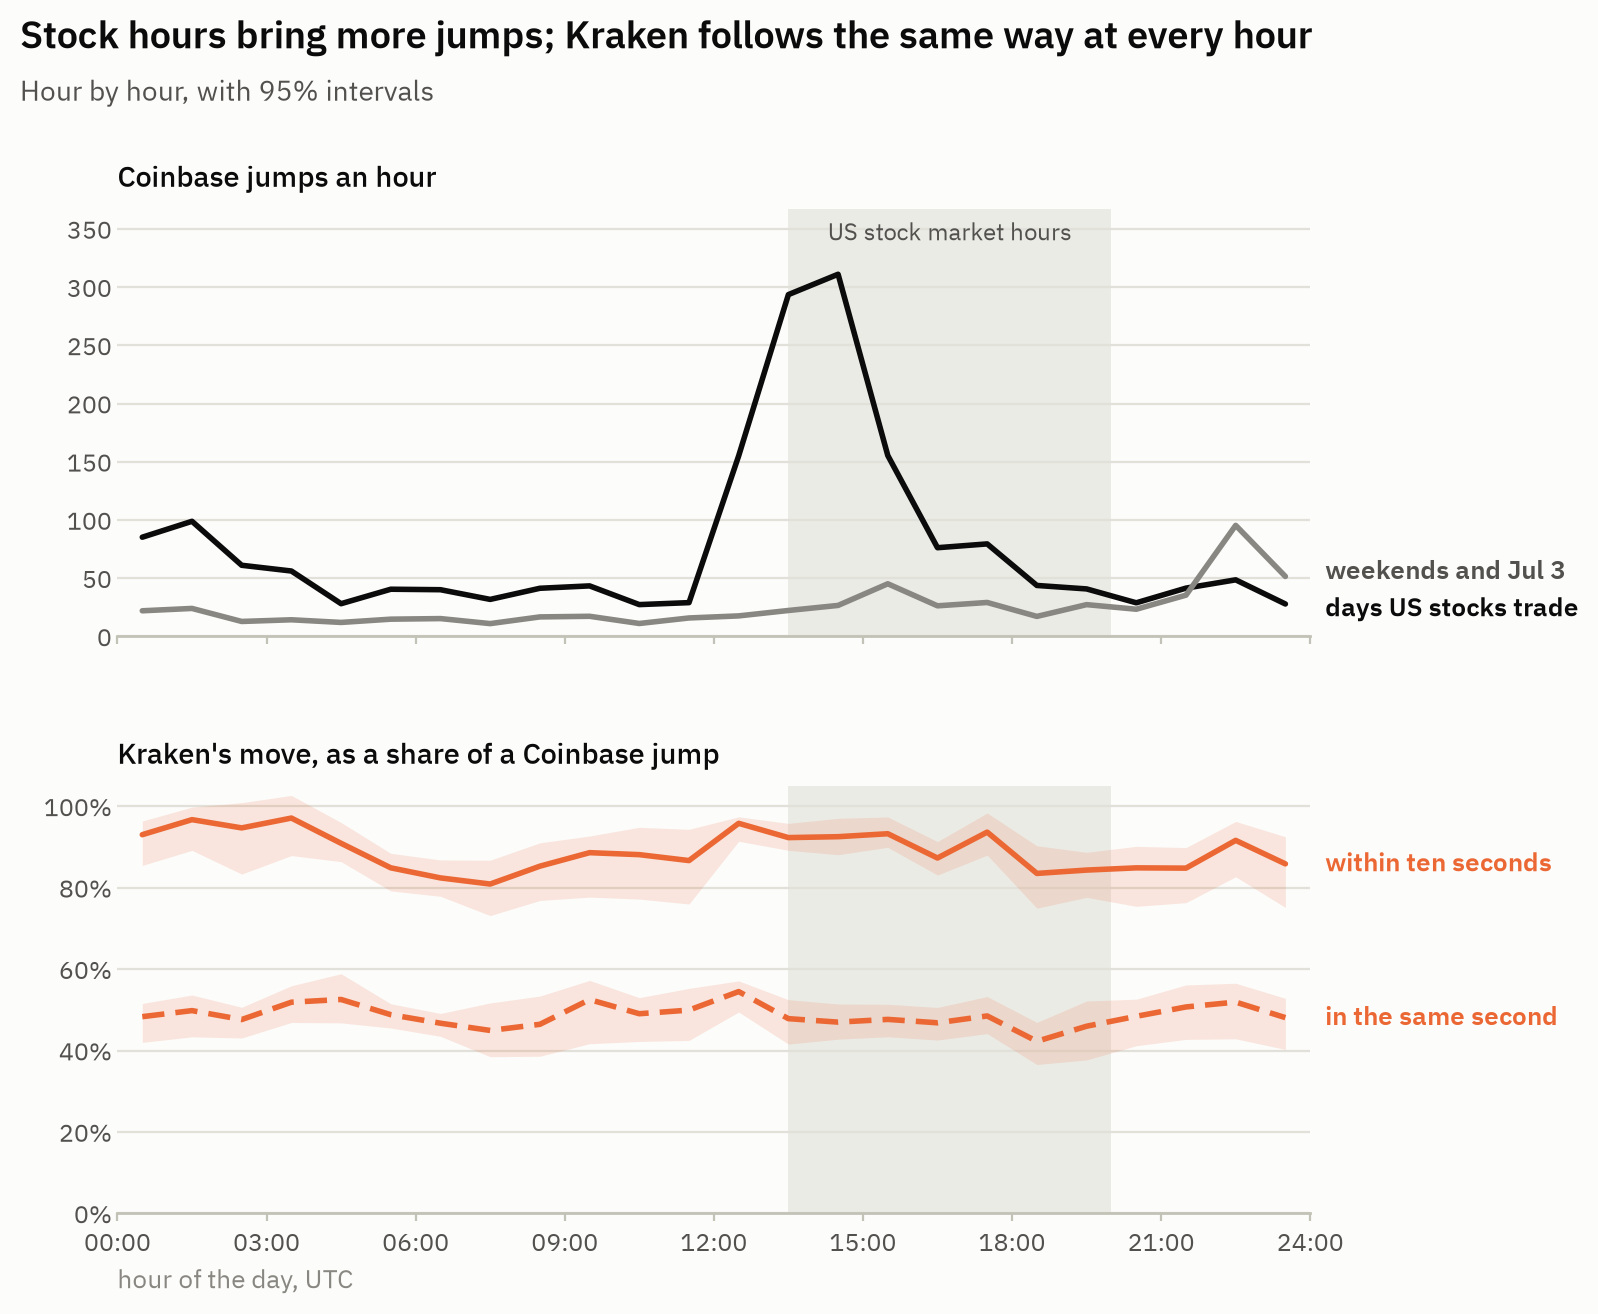

In [27]:
moves, bars = jump_moves(prices, 1)
hour = np.arange(24)


def per_hour(stocks):
    """Coinbase jumps an hour of bars, hour by hour, on days stocks did or did not trade."""
    keep = pl.col("stocks") == stocks
    n = moves.filter(keep).group_by("block").len("jumps")
    held = bars.filter(keep).group_by("block").agg(pl.col("bars").sum())
    rate = held.join(n, on="block", how="left").fill_null(0).sort("block")
    return (rate["jumps"] / rate["bars"] * 3600).to_numpy()


busy = {True: per_hour(True), False: per_hour(False)}
now = [share(moves.filter(pl.col("block") == h), "now") for h in hour]
ten = [share(moves.filter(pl.col("block") == h), "ten") for h in hour]
peak = int(np.argmax(busy[True]))
print(f"all {moves.height:,} of the essay's Coinbase jumps, placed by the hour they fell in")
print(f"Coinbase jumps an hour: at most {busy[True].max():.0f}, {peak:02d}-{peak + 1:02d} UTC on days "
      f"US stocks trade, against {busy[False][peak]:.0f} in that hour on other days")
print("hour by hour, Kraken's move as a share of Coinbase's:")
print(f"  in the jump's own second {min(p for p, _ in now):.0%} to {max(p for p, _ in now):.0%}, "
      f"within ten seconds {min(p for p, _ in ten):.0%} to {max(p for p, _ in ten):.0%}")

fig, (top, bottom) = plt.subplots(2, 1, figsize=(8.4, 6.6), sharex=True)
x = hour + 0.5
for ax in (top, bottom):
    ax.axvspan(13.5, 20, color=PALE, alpha=0.6, lw=0, zorder=0)
    ax.grid(axis="y")
note(top, 16.75, 0.97, "US stock market hours", transform=top.get_xaxis_transform(),
     ha="center", va="top", fontsize=8.5)
ends = []
for stocks, colour in ((True, INK), (False, MUTED)):
    top.plot(x, busy[stocks], color=colour, lw=2, zorder=3)
    ends.append(busy[stocks][-1])
for y, label, colour in zip(apart(ends, 32), ("days US stocks trade", "weekends and Jul 3"),
                            (INK, INK2)):
    name_series(top, 24.3, y, label, colour)
top.set_ylim(0, busy[True].max() * 1.18)
top.set_title("Coinbase jumps an hour")

lines = ((ten, "within ten seconds", "-"), (now, "in the same second", (0, (4, 2))))
for series, label, style in lines:
    point = np.array([p for p, _ in series])
    lo, hi = np.array([i for _, i in series]).T
    bottom.fill_between(x, lo, hi, color=KRAKEN, alpha=0.15, lw=0, zorder=2)
    bottom.plot(x, point, color=KRAKEN, lw=2, ls=style, zorder=3)
    name_series(bottom, 24.3, point[-1], label, KRAKEN)
bottom.set_ylim(0, 1.05)
bottom.yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0))
bottom.set_title("Kraken's move, as a share of a Coinbase jump")
bottom.set_xlim(0, 24)
bottom.set_xticks(range(0, 25, 3), [f"{h:02d}:00" for h in range(0, 25, 3)])
bottom.set_xlabel("hour of the day, UTC", loc="left")
headline(fig, "Stock hours bring more jumps; Kraken follows the same way at every hour",
         "Hour by hour, with 95% intervals", top=1.05, left=0.07, right=0.78, bottom=0.08,
         hspace=0.35)
plt.show()

# The text below quotes these.
assert moves.height == 22_446
assert f"{busy[True].max():.0f} {peak} {busy[False][peak]:.0f}" == "311 14 27"
assert [f"{f(p for p, _ in s):.0%}" for s in (now, ten) for f in (min, max)] == \
    ["42%", "55%", "81%", "97%"]

Hour by hour, on days US stocks trade, Coinbase jumps 311 times an hour from 14 to 15 UTC, the
first full hour after the New York open, against 27 in that hour on other days. Kraken's follow
shows no trace of it: across the 24 hours it makes 42% to 55% of Coinbase's move in the jump's
own second and 81% to 97% within ten, with no step at the open.

## 13. Inside the jump second

The essay's view inside the jump second was read from crosstick's lake, not from a run record.
`scripts/extract_jumps.py` read both venues' books around every jump the essay's rule finds, on
both clocks, and wrote a jump only if the arrival clock, rebuilt from those books, returned the
published mids at the jump's own bars. `scripts/export_jumps.py` checked that what came back
covers exactly the essay's jumps. The cell below repeats that check from the committed files,
then shows the result on both clocks and by day.

In [28]:
crossings = pl.read_parquet(DATA / "jump_crossings.parquet")
jump_paths = pl.read_parquet(DATA / "jump_paths.parquet")

# The essay's jumps, found again in the published prices by its own rule.
ts, day = prices["ts_ns"].to_numpy(), prices["date"].to_numpy()
logp = np.log(prices.select(["coinbase_mid", "kraken_mid"]).to_numpy()) * 1e4
follows = np.r_[False, (np.diff(ts) == 1_000_000_000) & (day[1:] == day[:-1])]
stretch = np.cumsum(~follows)
essay_jumps = []
for k, leader in enumerate(venues):
    move = np.r_[np.nan, np.diff(logp[:, k])]
    at = np.flatnonzero(follows & (np.abs(move) >= 2.0))
    at = at[(at >= 10) & (at + 15 < len(logp))]
    at = at[stretch[at - 10] == stretch[at + 15]]
    essay_jumps.append(pl.DataFrame({"date": day[at], "ts_ns": ts[at], "leader": leader,
                                     "sign": np.sign(move[at]).astype(np.int64)}))
key = ["date", "ts_ns", "leader", "sign"]
assert crossings.select(key).sort(key).equals(pl.concat(essay_jumps).sort(key))
print(f"the extraction covers exactly the essay's {crossings.height:,} jumps")


def lined_up(jumper, clock, by=()):
    """The other venue's average path around `jumper`'s crossings, from the lined_daily sums."""
    keys = [*by, "ms"]
    return (jump_paths.filter((pl.col("leader") == jumper) & (pl.col("clock") == clock))
            .group_by(keys).agg(pl.col("n", "other_sum").sum()).sort(keys)
            .with_columns(other=pl.col("other_sum") / pl.col("n")))


def made_by(a):
    at = dict(a.select("ms", "other").iter_rows())
    return at[0] / at[5000]


def halfway_at(a):
    end = a.filter(pl.col("ms") == 5000)["other"].item()
    return a.filter(pl.col("other") >= end / 2)["ms"][0]


def both_jumped(clock):
    """The seconds in which both prices jumped the same way, with how many ms Coinbase's
    crossing came before Kraken's."""
    cross = f"cross_{clock}_ms"
    return (crossings.filter(pl.col("leader") == "coinbase")
            .join(crossings.filter(pl.col("leader") == "kraken"), on=["date", "ts_ns", "sign"])
            .drop_nulls([cross, f"{cross}_right"])
            .with_columns(ahead=pl.col(f"{cross}_right") - pl.col(cross)))


inside, pairs = {}, {}
for clock in ("arrival", "exchange"):
    lined_all = {j: lined_up(j, clock) for j in venues}
    lined_daily = {j: [g for _, g in lined_up(j, clock, ["date"]).group_by("date", maintain_order=True)]
            for j in venues}
    # Each average is lined up on its own jumper's crossing: Coinbase's for Kraken's line,
    # Kraken's for Coinbase's.
    inside[clock] = {
        "kraken_made": (made_by(lined_all["coinbase"]), [made_by(g) for g in lined_daily["coinbase"]]),
        "coinbase_made": (made_by(lined_all["kraken"]), [made_by(g) for g in lined_daily["kraken"]]),
        "kraken_halfway": (halfway_at(lined_all["coinbase"]), [halfway_at(g) for g in lined_daily["coinbase"]]),
        "coinbase_halfway": (halfway_at(lined_all["kraken"]), [halfway_at(g) for g in lined_daily["kraken"]]),
    }
    pairs[clock] = both_jumped(clock)

print(f"\n{'':9s} {'jumps lined up':>16s}   {'Kraken at Coinbase crossing':>27s}   "
      f"{'Coinbase at Kraken crossing':>27s}")
for clock, r in inside.items():
    lined = {j: crossings.filter(pl.col("leader") == j)[f"cross_{clock}_ms"].is_not_null().sum()
             for j in venues}
    print(f"{clock:9s} {lined['coinbase']:>7,} and {lined['kraken']:>6,}   "
          f"{r['kraken_made'][0]:>9.0%} ({min(r['kraken_made'][1]):.0%} to {max(r['kraken_made'][1]):.0%} by day)   "
          f"{r['coinbase_made'][0]:>9.0%} ({min(r['coinbase_made'][1]):.0%} to {max(r['coinbase_made'][1]):.0%} by day)")

print(f"\nhalfway, ms after the other's crossing:  Kraken after Coinbase's   Coinbase after Kraken's")
for clock, r in inside.items():
    print(f"{clock:9s} {'':30s} {r['kraken_halfway'][0]:>5d} ({min(r['kraken_halfway'][1])} to "
          f"{max(r['kraken_halfway'][1])} by day)   {r['coinbase_halfway'][0]:>5d} "
          f"({min(r['coinbase_halfway'][1])} to {max(r['coinbase_halfway'][1])} by day)")

print("\nseconds in which both jumped the same way")
for clock, p in pairs.items():
    d = p.group_by("date").agg(first=(pl.col("ahead") > 0).mean(), median=pl.col("ahead").median())
    print(f"{clock:9s} {p.height:>6,}   Coinbase first in {(p['ahead'] > 0).mean():.1%} "
          f"({d['first'].min():.0%} to {d['first'].max():.0%} by day, at most half on "
          f"{(d['first'] <= 0.5).sum()}), a median {p['ahead'].median():.0f} ms ahead "
          f"({d['median'].min():.0f} to {d['median'].max():.0f} by day)")

missing = {j: crossings.filter(pl.col("leader") == j)["cross_exchange_ms"].null_count() for j in venues}
lost = pairs["arrival"].height - pairs["exchange"].height
as_kraken = (pairs["exchange"]["ahead"] > 0).sum() / pairs["arrival"].height
print(f"\nno crossing inside the second on the exchanges' stamps: {missing['coinbase']:,} Coinbase "
      f"jumps, {missing['kraken']:,} Kraken jumps, and {lost} of the {pairs['arrival'].height:,} "
      f"seconds both jumped; counting those as Kraken's leaves Coinbase first in {as_kraken:.1%}")
kraken_most = max(max(r["kraken_made"][1]) for r in inside.values())
coinbase_least = min(min(r["coinbase_made"][1]) for r in inside.values())
print(f"on every day and both clocks, Kraken has made at most {kraken_most:.0%} of its move at "
      f"Coinbase's crossing, and Coinbase at least {coinbase_least:.0%} of its move at Kraken's")

# The text below quotes these.
halfway = {c: (r["kraken_halfway"][0], r["coinbase_halfway"][0]) for c, r in inside.items()}
assert halfway == {"arrival": (340, -30), "exchange": (260, 10)}
arrival_days = pairs["arrival"].group_by("date").agg(
    first=(pl.col("ahead") > 0).mean(), median=pl.col("ahead").median())
stamp_days = pairs["exchange"].group_by("date").agg(first=(pl.col("ahead") > 0).mean())
assert f"{arrival_days['first'].min():.0%} {arrival_days['first'].max():.0%} " \
       f"{arrival_days['median'].min():.0f} {arrival_days['median'].max():.0f}" == "61% 84% 33 92"
assert f"{(pairs['exchange']['ahead'] > 0).mean():.1%} {stamp_days['first'].min():.0%} " \
       f"{stamp_days['first'].max():.0%} {(stamp_days['first'] <= 0.5).sum()}" == "54.2% 46% 74% 5"
assert f"{missing['coinbase']:,} {missing['kraken']:,} {lost} {pairs['arrival'].height:,} " \
       f"{as_kraken:.1%}" == "218 1,398 168 7,438 52.9%"
assert f"{kraken_most:.0%} {coinbase_least:.0%}" == "33% 41%"

the extraction covers exactly the essay's 46,281 jumps

            jumps lined up   Kraken at Coinbase crossing   Coinbase at Kraken crossing
arrival    22,446 and 23,835         16% (5% to 22% by day)         58% (48% to 66% by day)
exchange   22,228 and 22,437         25% (16% to 33% by day)         49% (41% to 64% by day)

halfway, ms after the other's crossing:  Kraken after Coinbase's   Coinbase after Kraken's
arrival                                    340 (210 to 440 by day)     -30 (-60 to 10 by day)
exchange                                   260 (110 to 380 by day)      10 (-50 to 60 by day)

seconds in which both jumped the same way
arrival    7,438   Coinbase first in 69.0% (61% to 84% by day, at most half on 0), a median 63 ms ahead (33 to 92 by day)
exchange   7,270   Coinbase first in 54.2% (46% to 74% by day, at most half on 5), a median 14 ms ahead (-14 to 33 by day)

no crossing inside the second on the exchanges' stamps: 218 Coinbase jumps, 1,398 Kraken jumps, and 168

Each average is lined up on its own jumper's crossing, which puts that venue ahead at zero
whichever venue it is, so each flatters its jumper. If the two prices moved together, the two
halfway times would be equal. On arrival Kraken is halfway 340 ms after Coinbase's crossing and
Coinbase 30 ms before Kraken's; on the stamps, 260 ms and 10 ms after. The seconds in which
both jumped the same way flatter neither venue. On arrival Coinbase's price crosses first in
61% to 84% of them by day, a median 33 to 92 ms ahead. On the stamps it crosses first in 54.2%,
between 46% and 74% by day, and in no more than half on 5 of the 20 days.

On the stamps, 218 Coinbase jumps and 1,398 Kraken jumps have no crossing inside their second.
The second was cut on the arrival clock, and on the stamps part of those moves falls before it,
so they drop out of that clock's averages, taking 168 of the 7,438 seconds both jumped with
them. Counted as Kraken's, those 168 would leave Coinbase first in 52.9%. On every day and on
both clocks Kraken has made at most 33% of its move by Coinbase's crossing, and Coinbase at
least 41% of its move by Kraken's.

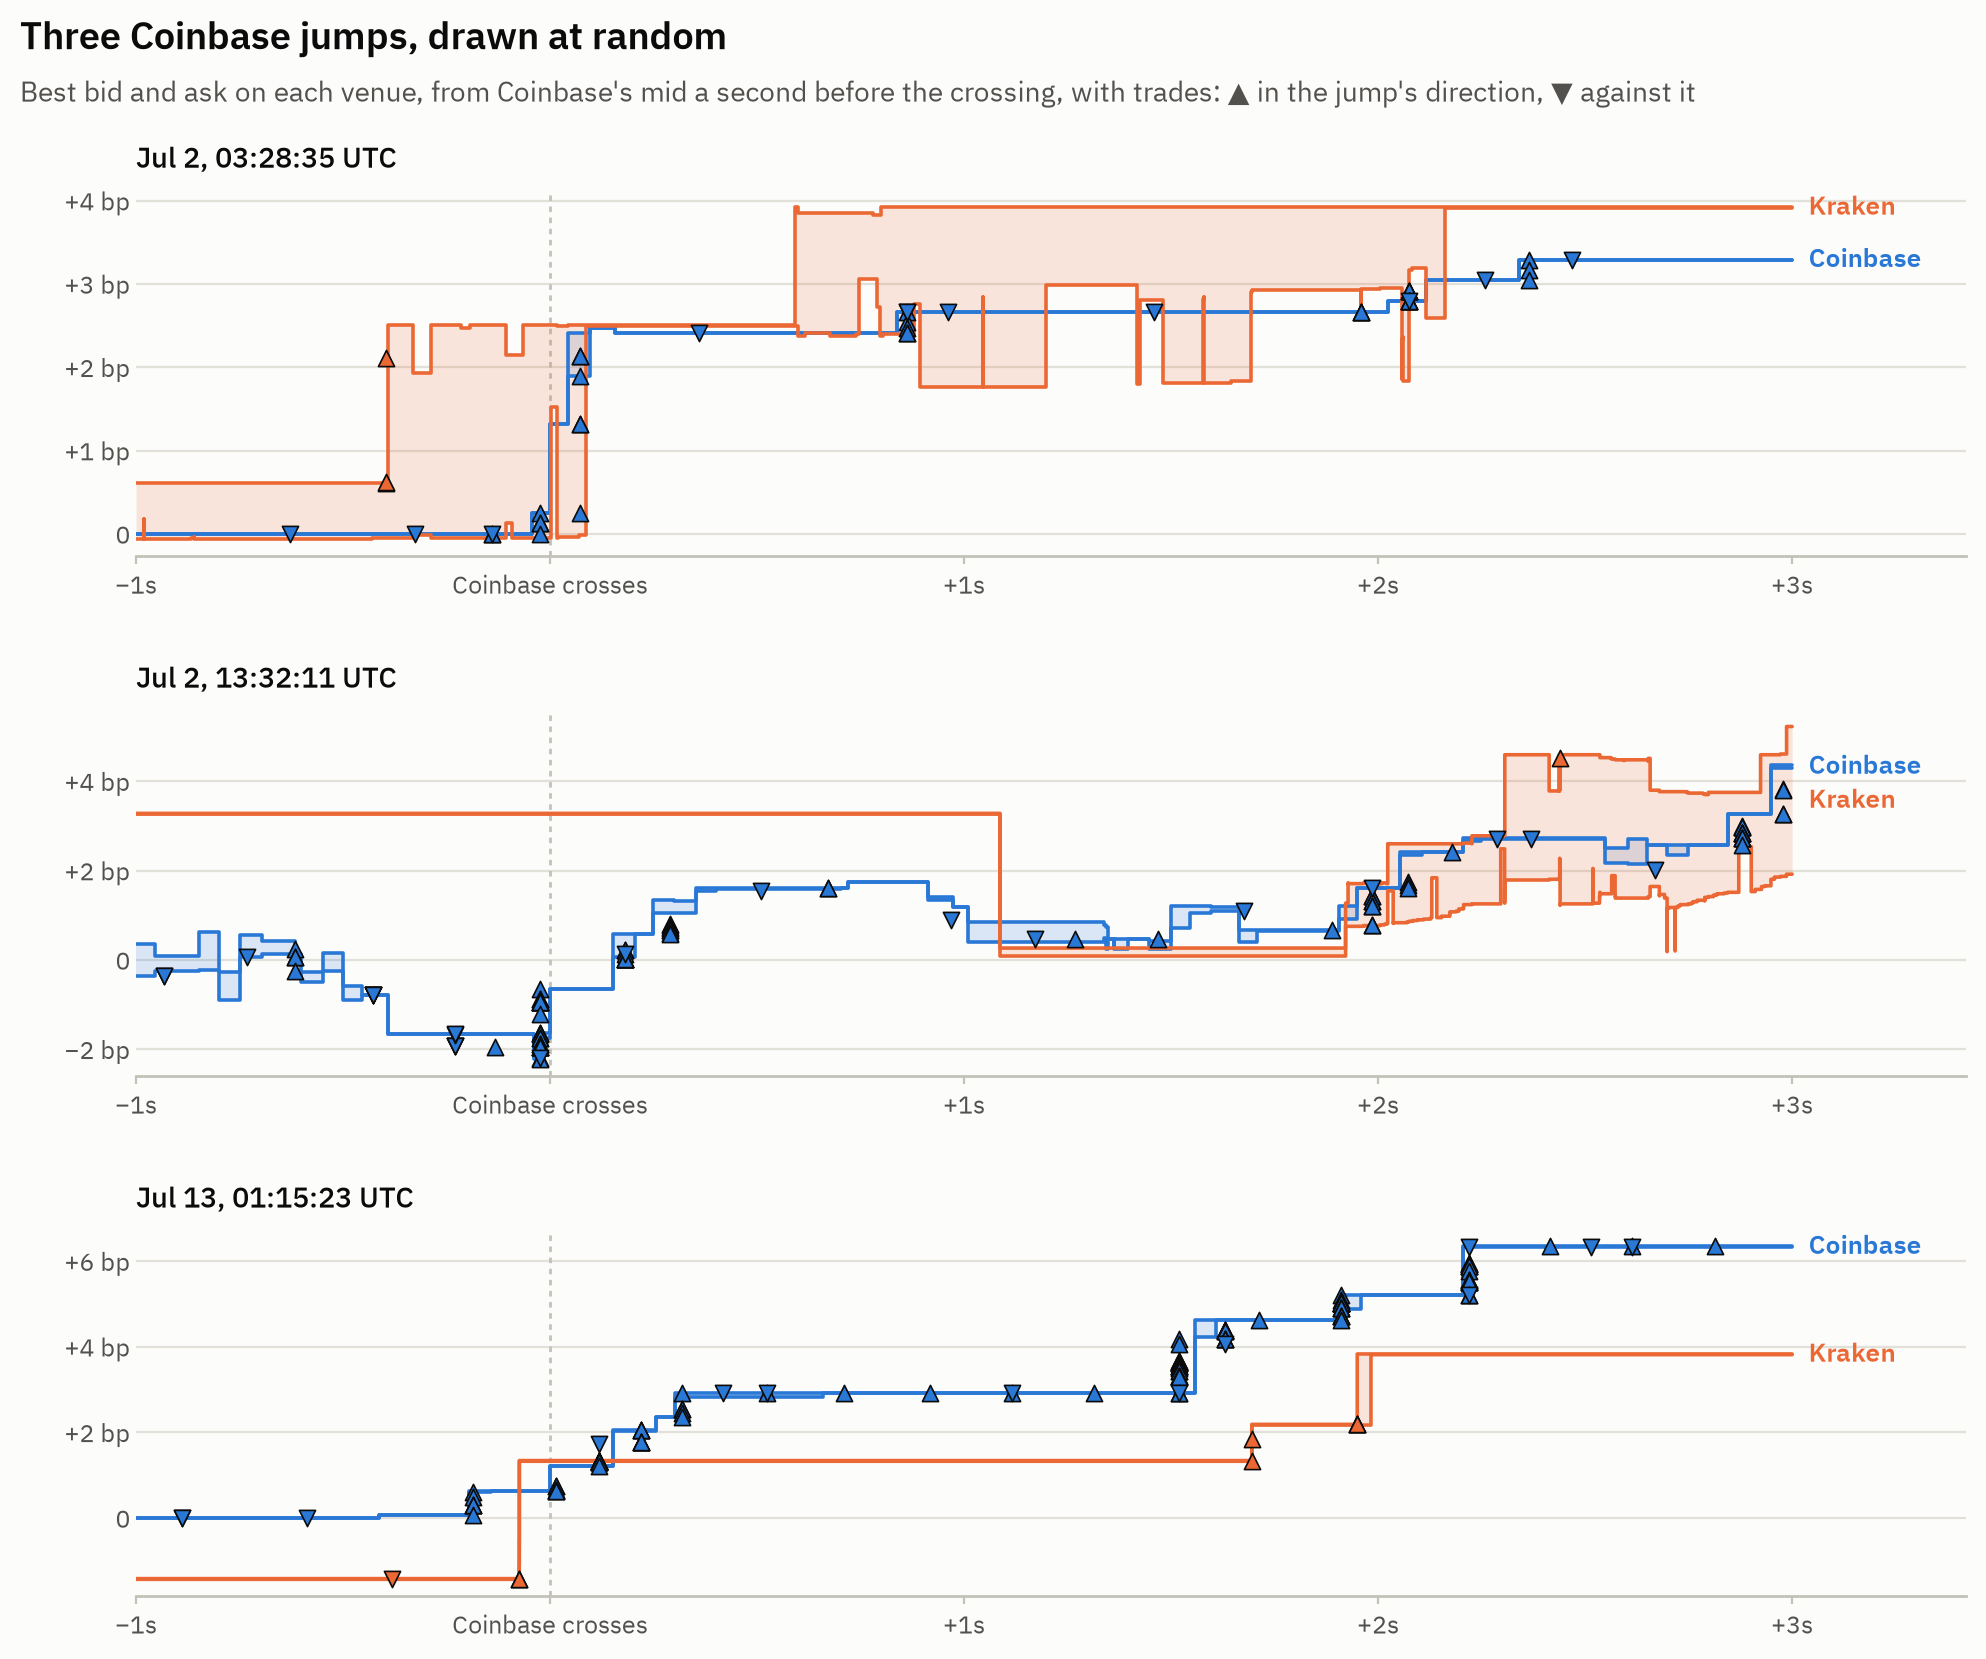

07-02: Coinbase crosses 512 ms into the second; Kraken's best prices first change 2 ms after it, and its mid first stands 1 bp above where it was a second before +2 ms from the crossing
07-02: Coinbase crosses 264 ms into the second; Kraken's best prices first change 1,087 ms after it, and its mid first stands 1 bp above where it was a second before at no point in the next 3 s
07-13: Coinbase crosses 348 ms into the second; Kraken's best prices first change 1,695 ms after it, and its mid first stands 1 bp above where it was a second before -74 ms from the crossing


In [29]:
events = pl.read_parquet(DATA / "jump_events.parquet")
drawn_with = json.loads(pq.read_schema(DATA / "jump_paths.parquet").metadata[b"crosstick"])
# The essay's three Coinbase jumps, drawn at random.
coinbase_jumps = crossings.filter(pl.col("leader") == "coinbase").sort("ts_ns")
pick = np.sort(np.random.default_rng(drawn_with["event_seed"]).choice(coinbase_jumps.height, 3,
                                                                      replace=False))
drawn = coinbase_jumps[pick].select("date", "ts_ns").rows()
assert drawn == [tuple(e) for e in drawn_with["events"]]
assert sorted(events.select("date", "jump_ts_ns").unique().rows()) == drawn


def bp(price, ref, sign):
    return (np.log(price) - ref) * 1e4 * sign


fig, axes = plt.subplots(3, 1, figsize=(10, 8.4), sharex=True)
for ax, (date, jump) in zip(axes, drawn):
    e = events.filter((pl.col("date") == date) & (pl.col("jump_ts_ns") == jump))
    c, sign = e["cross_ns"][0], e["sign"][0]
    book = e.filter(pl.col("kind") == "book").sort("ts_ns")
    before = book.filter((pl.col("venue") == "coinbase") & (pl.col("ts_ns") <= c - 1_000_000_000))[-1]
    ref = np.log((before["bid"].item() + before["ask"].item()) / 2)
    for venue, colour, name in (("coinbase", COINBASE, "Coinbase"), ("kraken", KRAKEN, "Kraken")):
        # The quote standing at -1 s, then every update to +3 s; the extract runs -2 s to +5 s.
        b = book.filter(pl.col("venue") == venue)
        ms = (b["ts_ns"].to_numpy() - c) / 1e6
        b = b[max(np.searchsorted(ms, -1000, "right") - 1, 0):np.searchsorted(ms, 3000, "right")]
        x = np.r_[np.maximum((b["ts_ns"].to_numpy() - c) / 1e6, -1000), 3000]
        low, high = (np.r_[bp(b[side].to_numpy(), ref, sign), np.nan] for side in ("bid", "ask"))
        low[-1], high[-1] = low[-2], high[-2]
        lo, hi = np.minimum(low, high), np.maximum(low, high)
        ax.fill_between(x, lo, hi, step="post", color=colour, alpha=0.16, lw=0, zorder=2)
        for y in (lo, hi):
            ax.step(x, y, where="post", color=colour, lw=1.3, zorder=3)
        t = e.filter((pl.col("kind") == "trade") & (pl.col("venue") == venue)
                     & pl.col("ts_ns").is_between(c - 1_000_000_000, c + 3_000_000_000))
        tx, ty = (t["ts_ns"].to_numpy() - c) / 1e6, bp(t["price"].to_numpy(), ref, sign)
        with_jump = t["taker"].to_numpy() == sign
        for keep, marker in ((with_jump, "^"), (~with_jump, "v")):
            ax.scatter(tx[keep], ty[keep], marker=marker, s=34, color=colour, edgecolor=INK,
                       lw=0.6, zorder=5)
        name_series(ax, 3040, (lo[-1] + hi[-1]) / 2, name, colour)
    ax.axvline(0, color=AXIS, lw=1, ls=(0, (2, 2)), zorder=1)
    when = datetime.fromtimestamp(c / 1e9, tz=timezone.utc)
    ax.set_title(f"{when:%b} {when.day}, {when:%H:%M:%S} UTC")
    ax.yaxis.set_major_formatter(signed("bp"))
    ax.tick_params(axis="x", labelbottom=True)
    ax.grid(axis="y")
axes[-1].set_xticks([-1000, 0, 1000, 2000, 3000],
                    ["−1s", "Coinbase crosses", "+1s", "+2s", "+3s"])
axes[-1].set_xlim(-1000, 3420)
headline(fig, "Three Coinbase jumps, drawn at random",
         "Best bid and ask on each venue, from Coinbase's mid a second before the crossing, "
         "with trades: ▲ in the jump's direction, ▼ against it",
         top=0.95, left=0.07, right=0.985, bottom=0.05, hspace=0.42)
plt.show()

for date, jump in drawn:
    e = events.filter((pl.col("date") == date) & (pl.col("jump_ts_ns") == jump))
    c, sign = e["cross_ns"][0], e["sign"][0]
    k = e.filter((pl.col("venue") == "kraken") & (pl.col("kind") == "book")).sort("ts_ns")
    ms = (k["ts_ns"].to_numpy() - c) / 1e6
    mid = np.log((k["bid"].to_numpy() + k["ask"].to_numpy()) / 2) * 1e4
    rel = sign * (mid - mid[np.searchsorted(ms, -1000, "right") - 1])
    first = ms[(ms > -1000) & (ms <= 3000) & (rel >= 1.0)]
    at = np.searchsorted(ms, 0, "right") - 1
    quotes = np.c_[k["bid"].to_numpy(), k["ask"].to_numpy()]
    changed = ms[(ms > 0) & (quotes != quotes[at]).any(axis=1)]
    print(f"{date[5:]}: Coinbase crosses {(c - (jump - 1_000_000_000)) / 1e6:.0f} ms into the second; "
          f"Kraken's best prices first change {changed[0]:,.0f} ms after it, and its mid first stands "
          "1 bp above where it was a second before "
          + (f"{first[0]:+.0f} ms from the crossing" if len(first) else "at no point in the next 3 s"))

Three of the Coinbase jumps, drawn at random, show what the averages are made of: both venues'
best bid and ask, and every trade, marked by the side that took liquidity, with Coinbase's
flipped as section 2 describes. Single jumps are untidy. In the first, Kraken's mid stands 1 bp
up 2 ms after Coinbase's crossing. In the third it gets there 74 ms before the crossing, on
buying at Kraken, and steps up twice more over the next two seconds. In the second, Coinbase is
climbing back from a fall, Kraken's best prices do not change until 1,087 ms after the
crossing, and its mid never stands 1 bp up in the next three. The averages, not any one jump,
carry the result.

## 14. Everything, recomputed

The cell below recomputes every published number from the committed files and checks it against
the record: the forecasts' scores from the prediction rows, and every daily information-share
estimate from the one-second prices, refitted with crosstick's own estimator, across holes as
it made them. CI executes this notebook, so a number that drifts fails the build rather than
quietly rendering a different result.

In [30]:
checks = []

for tag, rec in [("real", real), ("reverse", backward), ("placebo", placebo)]:
    pooled_tag = confidence_intervals(rows(tag))
    for metric in ("r2_vs_zero", "hit_rate", "gross_bps_per_trade"):
        got, want = pooled_tag[metric], rec["pooled"]["gbt"][metric]
        ok = np.allclose(got, want, atol=1e-9, equal_nan=True)
        checks.append(ok)
        print(f"{tag:8s} {metric:20s} {got[0]:9.5f} [{got[1]:8.5f}, {got[2]:8.5f}]  "
              f"{'matches record' if ok else 'DIFFERS'}")

classes = class_confidence_intervals(rows("real"))
for metric in ("up_precision", "down_precision"):
    got, want = classes[metric], real["classes"]["gbt"][metric]
    ok = np.allclose(got, want, atol=1e-9)
    checks.append(ok)
    print(f"{'real':8s} {metric:20s} {got[0]:9.5f} [{got[1]:8.5f}, {got[2]:8.5f}]  "
          f"{'matches record' if ok else 'DIFFERS'}")

refits = []
for block in real["infoshare"]:
    for want in block["estimates"]:
        got = information_shares(days[want["date"]][:: block["stride"]], venues, block["lags"])
        refits.append(got.n == want["n"]
                      and np.allclose(got.alpha, want["alpha"], rtol=1e-9, atol=0)
                      and np.allclose(got.bounds, want["bounds"], rtol=0, atol=1e-9))
print(f"\ninformation share: {sum(refits)} of {len(refits)} daily estimates, across "
      f"{len(real['infoshare'])} sampling intervals, refitted from the prices and matching")

assert all(checks) and all(refits), "a published number does not reproduce from the files"
print(f"{len(checks)} forecast scores and {len(refits)} information-share estimates "
      f"recomputed, all matching")

real     r2_vs_zero             0.10349 [ 0.09075,  0.11202]  matches record


real     hit_rate               0.75719 [ 0.73511,  0.78052]  matches record
real     gross_bps_per_trade    0.20024 [ 0.15078,  0.24480]  matches record


reverse  r2_vs_zero             0.01076 [ 0.00814,  0.01437]  matches record
reverse  hit_rate               0.58163 [ 0.56915,  0.59704]  matches record
reverse  gross_bps_per_trade    0.09110 [ 0.07484,  0.10704]  matches record
placebo  r2_vs_zero            -0.00010 [-0.00028,  0.00011]  matches record
placebo  hit_rate               0.50352 [ 0.49580,  0.51244]  matches record
placebo  gross_bps_per_trade   -0.00088 [-0.00379,  0.00231]  matches record


real     up_precision           0.16165 [ 0.13223,  0.18758]  matches record
real     down_precision         0.15363 [ 0.12165,  0.18260]  matches record



information share: 60 of 60 daily estimates, across 3 sampling intervals, refitted from the prices and matching
11 forecast scores and 60 information-share estimates recomputed, all matching


`gross_bps_per_trade` is the average five-second move in the direction the model called, before
fees, the spread or any question of being filled. It is in the record because crosstick
computes it, and it is not a trading result.

---

**Data and code.** The predictions, prices and run records in `data/` were exported from
[crosstick](https://github.com/ryanp2718/crosstick) at commit `fb7a22d`, which is also the
commit this notebook installs its analysis code from. The re-timed prices and the clock
measurements were read from crosstick's lake by `scripts/extract_clocks.py`, and the
millisecond prices around the jumps by `scripts/extract_jumps.py`. The platform side, an
ingest-to-lake pipeline for three exchanges with reconstructed order books and a cross-exchange
NBBO, lives there.

**References.** Hasbrouck, "One security, many markets: determining the contributions to price
discovery", Journal of Finance 50(4), 1995. Gonzalo and Granger, "Estimation of common
long-memory components in cointegrated systems", Journal of Business and Economic Statistics
13(1), 1995. MacKinnon, "Numerical distribution functions for unit root and cointegration
tests", Journal of Applied Econometrics 11(6), 1996.